# Modelos Lineales Generalizados (GLM)


In [ ]:
# ==========================
# Entorno PyMC + PreliZ para Colab actual
# ==========================

!pip uninstall -y \
    pymc \
    pytensor \
    preliz \
    arviz \
    arviz_stats \
    numba \
    llvmlite


!pip install -q --no-cache-dir \
    "numpy==2.0.2" \
    "scipy==1.16.1" \
    "pandas==2.3.0" \
    "matplotlib==3.10.0" \
    "arviz==0.22.0" \
    "pytensor==2.38.3" \
    "pymc==5.28.5" \
    "preliz==0.20.0" \
    "xarray" \
    "bambi==0.15.0"

print("Instalación terminada.")
print("Ahora reiniciá la sesión: Runtime → Restart session")

In [ ]:
# trabajen con cualquiera de las dos celdas siguientes, teniendo en cuenta el entorno/aplicación con la que ejecuten este módulo

In [ ]:
import sys
import numpy as np
import scipy
import pandas as pd
import arviz as az
import pytensor
import pymc as pm
import preliz as pz
import xarray as xr

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("ArviZ:", az.__version__)
print("PyTensor:", pytensor.__version__)
print("PyMC:", pm.__version__)
print("PreliZ:", pz.__version__)
print("Xarray:", xr.__version__)

In [ ]:
import arviz as az
import pymc as pm
import preliz as pz

import numpy as np
import scipy.stats as stats
import pandas as pd
import matplotlib.pyplot as plt

#| code-fold: true

import bambi as bmb
#import kulprit as kpt
from scipy.interpolate import PchipInterpolator
from scipy.stats import linregress
import xarray as xr

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

az.style.use("arviz-doc")

In [ ]:
#| code-fold: true

plt.style.use('arviz-doc')

# Modelo lineal bayesiano

## **Recordemos el modelo lineal**

Supongamos que queremos estudiar la relación entre una variable predictora $X$ y una variable respuesta $Y$.

En un modelo lineal bayesiano podemos plantear:

$$ Y_i \sim \mathcal{N}(\mu_i,\sigma²) $$

donde la media depende linealmente de $X$:

$$ \mu_i = \alpha + \beta X_i. $$

Los parámetros tienen una interpretación sencilla:

* $\alpha$: intercepto, valor esperado de $Y$ cuando $X=0$.
* $\beta$: pendiente, cambio esperado en $Y$ cuando $X$ aumenta una unidad.
* $\sigma$: variabilidad de las observaciones alrededor de la relación media.

Desde el enfoque bayesiano, no buscamos solamente un valor para cada parámetro. Asignamos distribuciones a priori y, a partir de los datos, obtenemos las correspondientes distribuciones a posteriori.

## **Un ejemplo: temperatura y bicicletas**

Vamos a trabajar con un conjunto de datos que contiene información sobre:

**temperatura:** temperatura registrada;
**alquiladas:** cantidad de bicicletas alquiladas.

Nuestro objetivo será estudiar si existe una relación entre ambas variables.

<font color="orange"> NOTA: Usaremos bike-sharing dataset del repositorio UCI Machine Learning Repository. El conjunto original del tutorial, contiene 17 variables con 17379 registros. "bicis.csv" tiene solo 348 registros, y dos variables temperatura y alquiladas.

In [ ]:
bicis = pd.read_csv("bicis.csv")

bicis.head()

,alquiladas,hora,temperatura,humedad,viento
0,16,0,3.278960,0.81,0.0000
1,3,5,-0.478281,0.47,0.2836
2,115,9,2.339676,0.37,0.3284
3,73,13,1.399812,0.37,0.2836
4,82,15,2.339100,0.35,0.3582


Podemos comenzar mirando los datos:

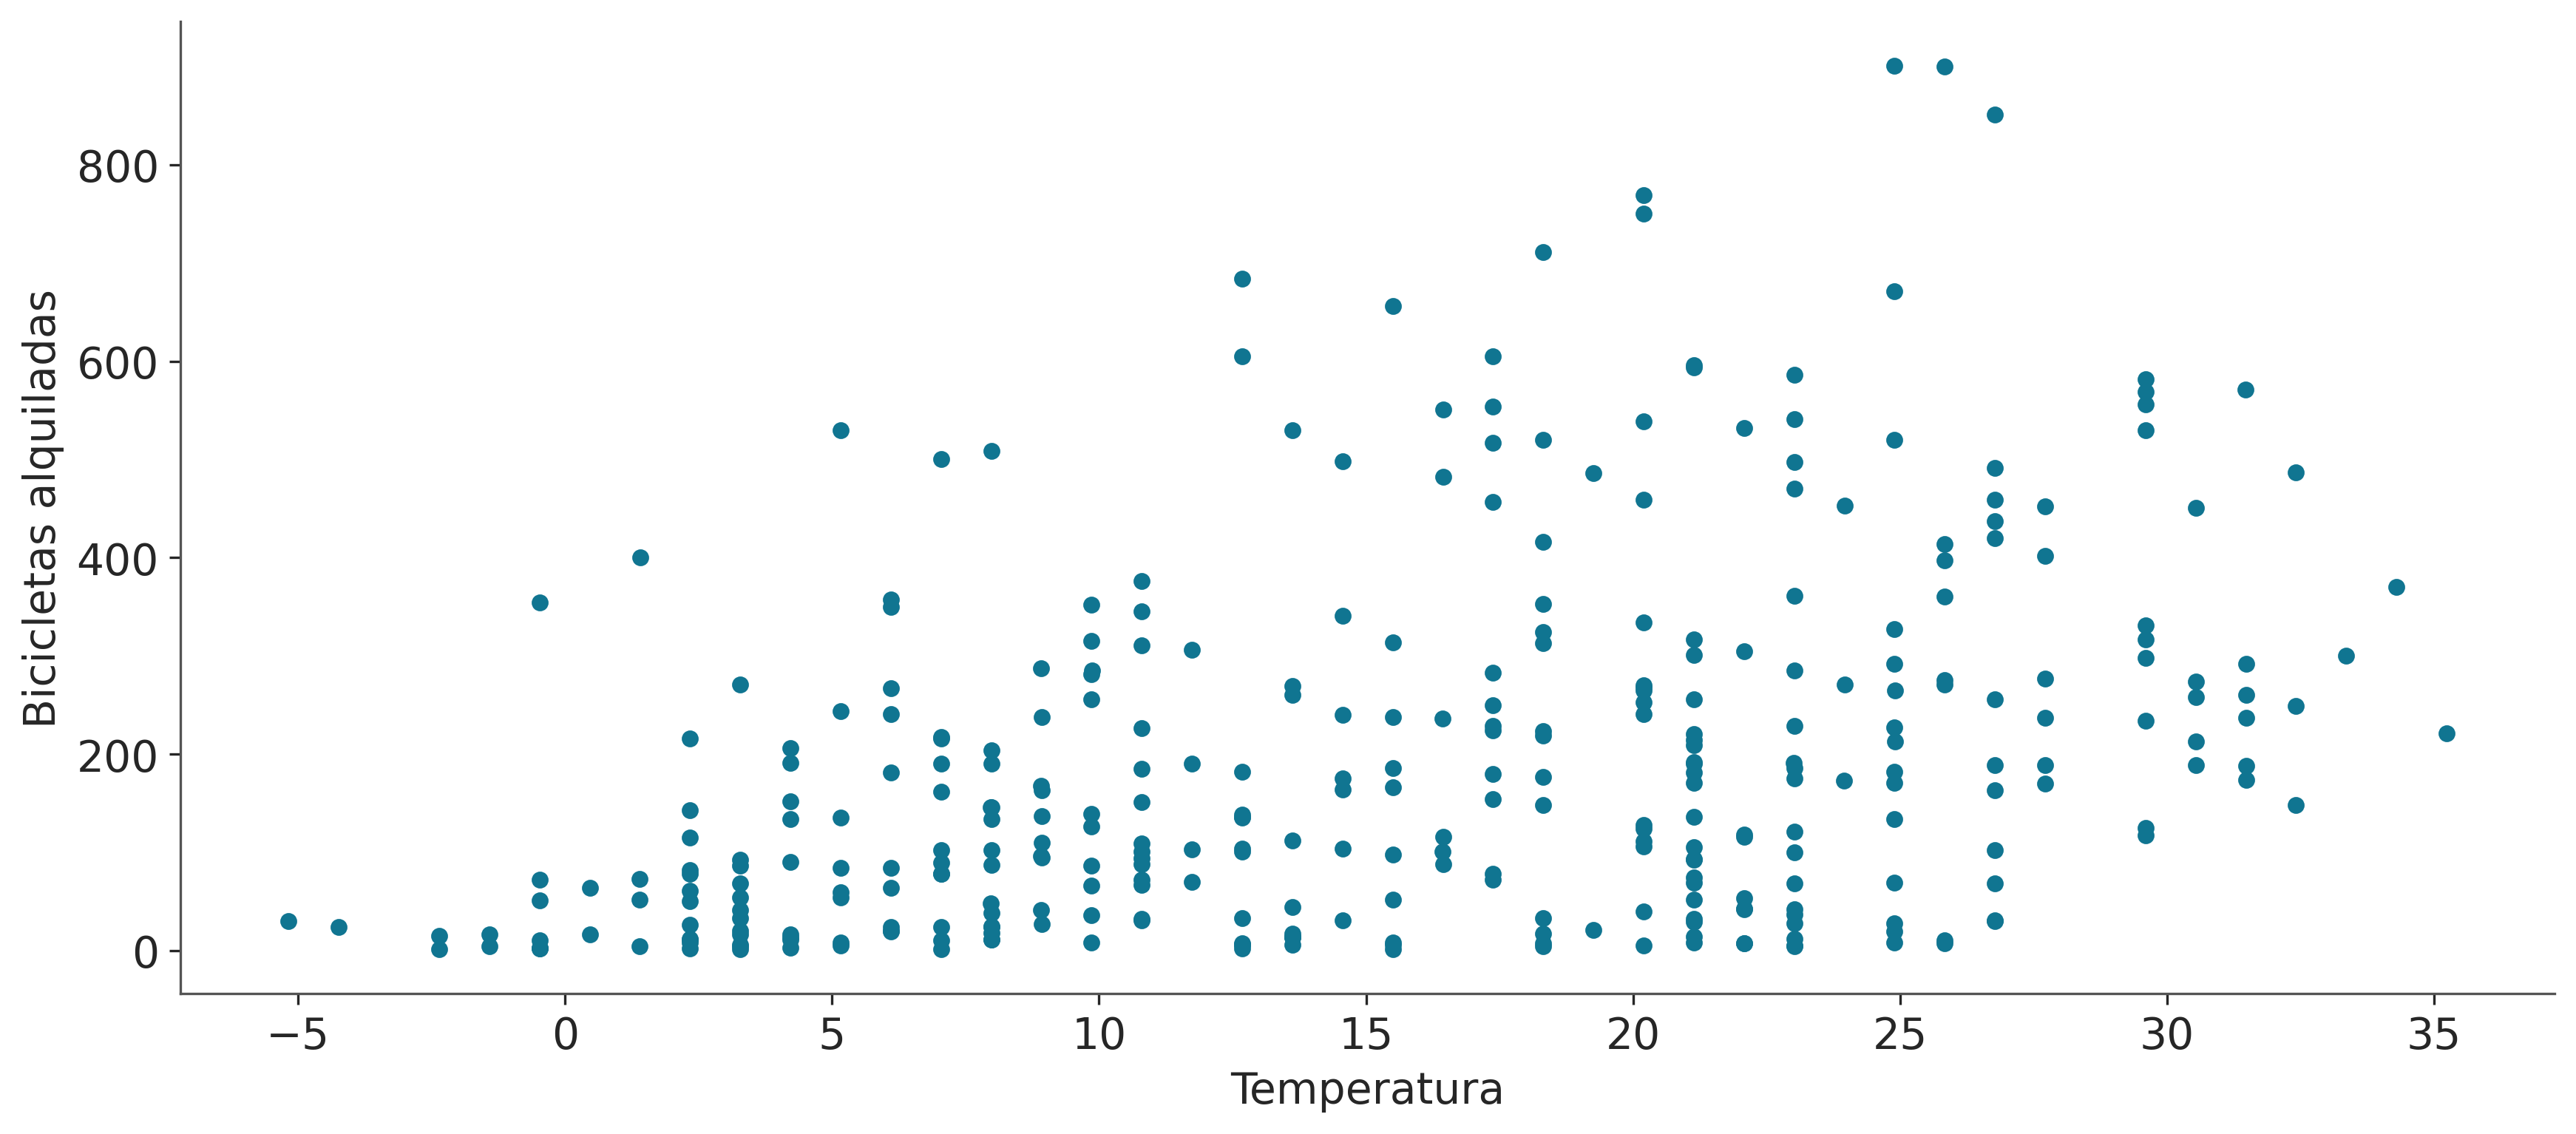

In [ ]:
bicis.plot(
    x="temperatura",
    y="alquiladas",
    kind="scatter"
);

plt.xlabel("Temperatura")
plt.ylabel("Bicicletas alquiladas")
plt.show()

A simple vista podemos preguntarnos:

¿Podemos representar la cantidad esperada de bicicletas alquiladas como una función de la temperatura?

## **Construimos el modelo con PyMC**

Planteamos:

$$ \begin{aligned} \mu_i &= \alpha+\beta X_i\\ Y_i &\sim \mathcal{N}(\mu_i,\sigma²) \end{aligned} $$


In [ ]:
with pm.Model() as modelo_bl:

    alpha = pm.Normal("alpha", mu=0, sigma=100)

    beta = pm.Normal("beta", mu=0, sigma=10)

    sigma = pm.HalfCauchy("sigma", beta=10)

    mu = alpha + beta * bicis["temperatura"]

    y_pred = pm.Normal(
        "y_pred",
        mu=mu,
        sigma=sigma,
        observed=bicis.alquiladas
    )

Podemos visualizar la estructura del modelo:

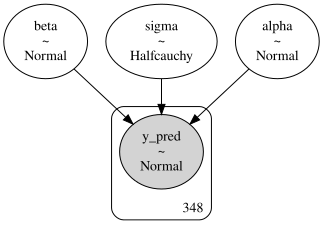

In [ ]:
pm.model_to_graphviz(modelo_bl)

Y obtener muestras de la distribución a posteriori:

In [ ]:
with modelo_bl:
    idata_bl = pm.sample(
        random_seed=123
    )

Output()

## **¿Qué aprendimos sobre los parámetros?**

Podemos visualizar las distribuciones a posteriori:




In [ ]:
az.plot_posterior(
    idata_bl,
    var_names=["alpha", "beta", "sigma"]
);

plt.show()

Lo importante es que ahora podemos interpretar los parámetros incorporando su incertidumbre, cosa que antes, sin un modelo bayesiano, requería de otros métodos de análisis...

Por ejemplo, si la distribución posterior de $\beta\$ está concentrada en valores positivos, los datos proporcionan evidencia de una relación positiva entre temperatura y cantidad de bicicletas alquiladas.

En lugar de decir simplemente:

$$ \beta = 8 $$

podemos hablar de una distribución de valores plausibles para $\beta$.

Por ejemplo, para cada aumento de un grado en la temperatura, esperamos un aumento en la cantidad de bicicletas alquiladas, aunque existe incertidumbre sobre la magnitud exacta de ese aumento.

## **La incertidumbre sobre la recta**

Una particularidad del enfoque bayesiano es que la recta también tiene incertidumbre. Cada combinación posible de $\alpha$ y $\beta$ genera una recta diferente:

$$ \mu = \alpha+\beta X. $$

Por eso, en lugar de obtener una única recta, podemos obtener muchas rectas compatibles con la distribución a posteriori.

In [ ]:
posterior = az.extract(
    idata_bl,
    num_samples=50
)

x = pd.Series(
    range(
        int(bicis.temperatura.min()),
        int(bicis.temperatura.max()) + 1
    )
)

lineas = (
    posterior["alpha"].values[:, None]
    + posterior["beta"].values[:, None] * x.values
)

Podemos visualizar algunas de ellas:

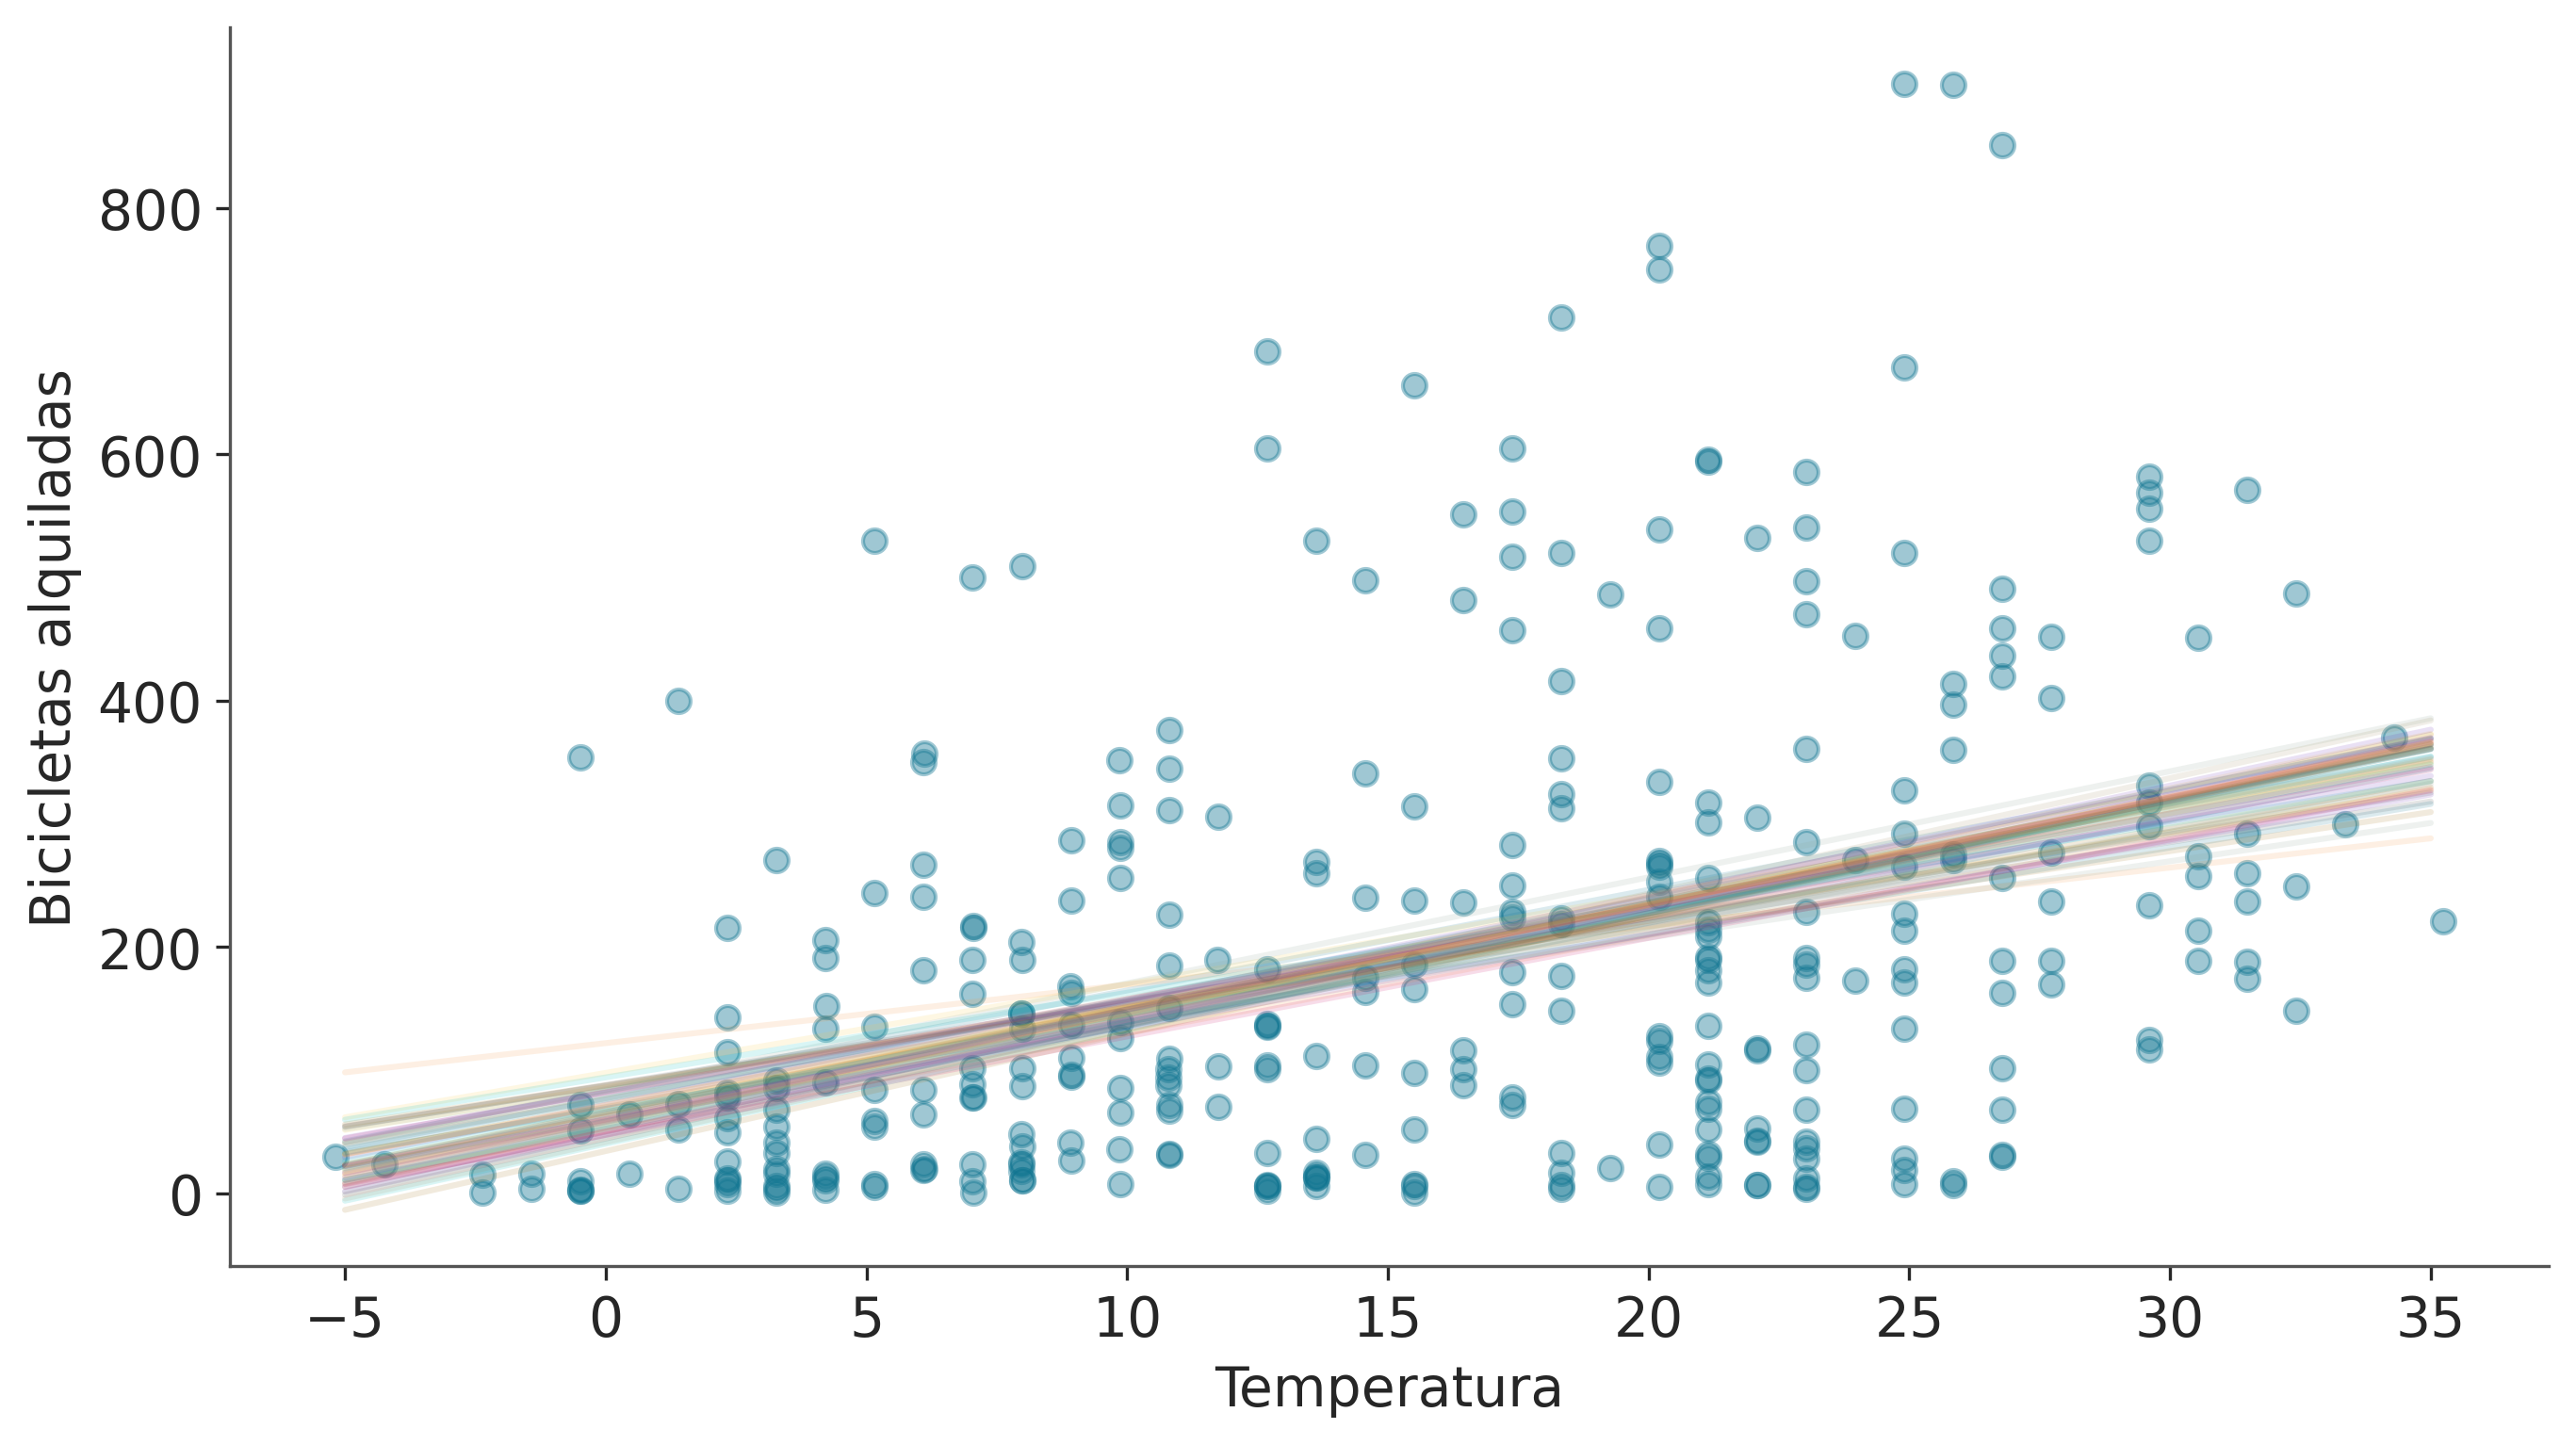

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    bicis.temperatura,
    bicis.alquiladas,
    alpha=0.4
)

plt.plot(
    x,
    lineas.T,
    alpha=0.15
)

plt.xlabel("Temperatura")
plt.ylabel("Bicicletas alquiladas")

plt.show()

La incertidumbre de los parámetros se traduce en incertidumbre sobre la relación entre $X$ e $Y$.

## **De la media a la predicción**

Hasta ahora hablamos de $\mu$, es decir, del valor medio esperado. Pero muchas veces queremos responder una pregunta diferente, ¿Cuántas bicicletas podríamos observar realmente cuando la temperatura sea determinada?

Para eso necesitamos la **distribución predictiva posterior**.

In [ ]:
with modelo_bl: pm.sample_posterior_predictive( idata_bl, extend_inferencedata=True, random_seed=123 )

Output()

visualicemos las predicciones:

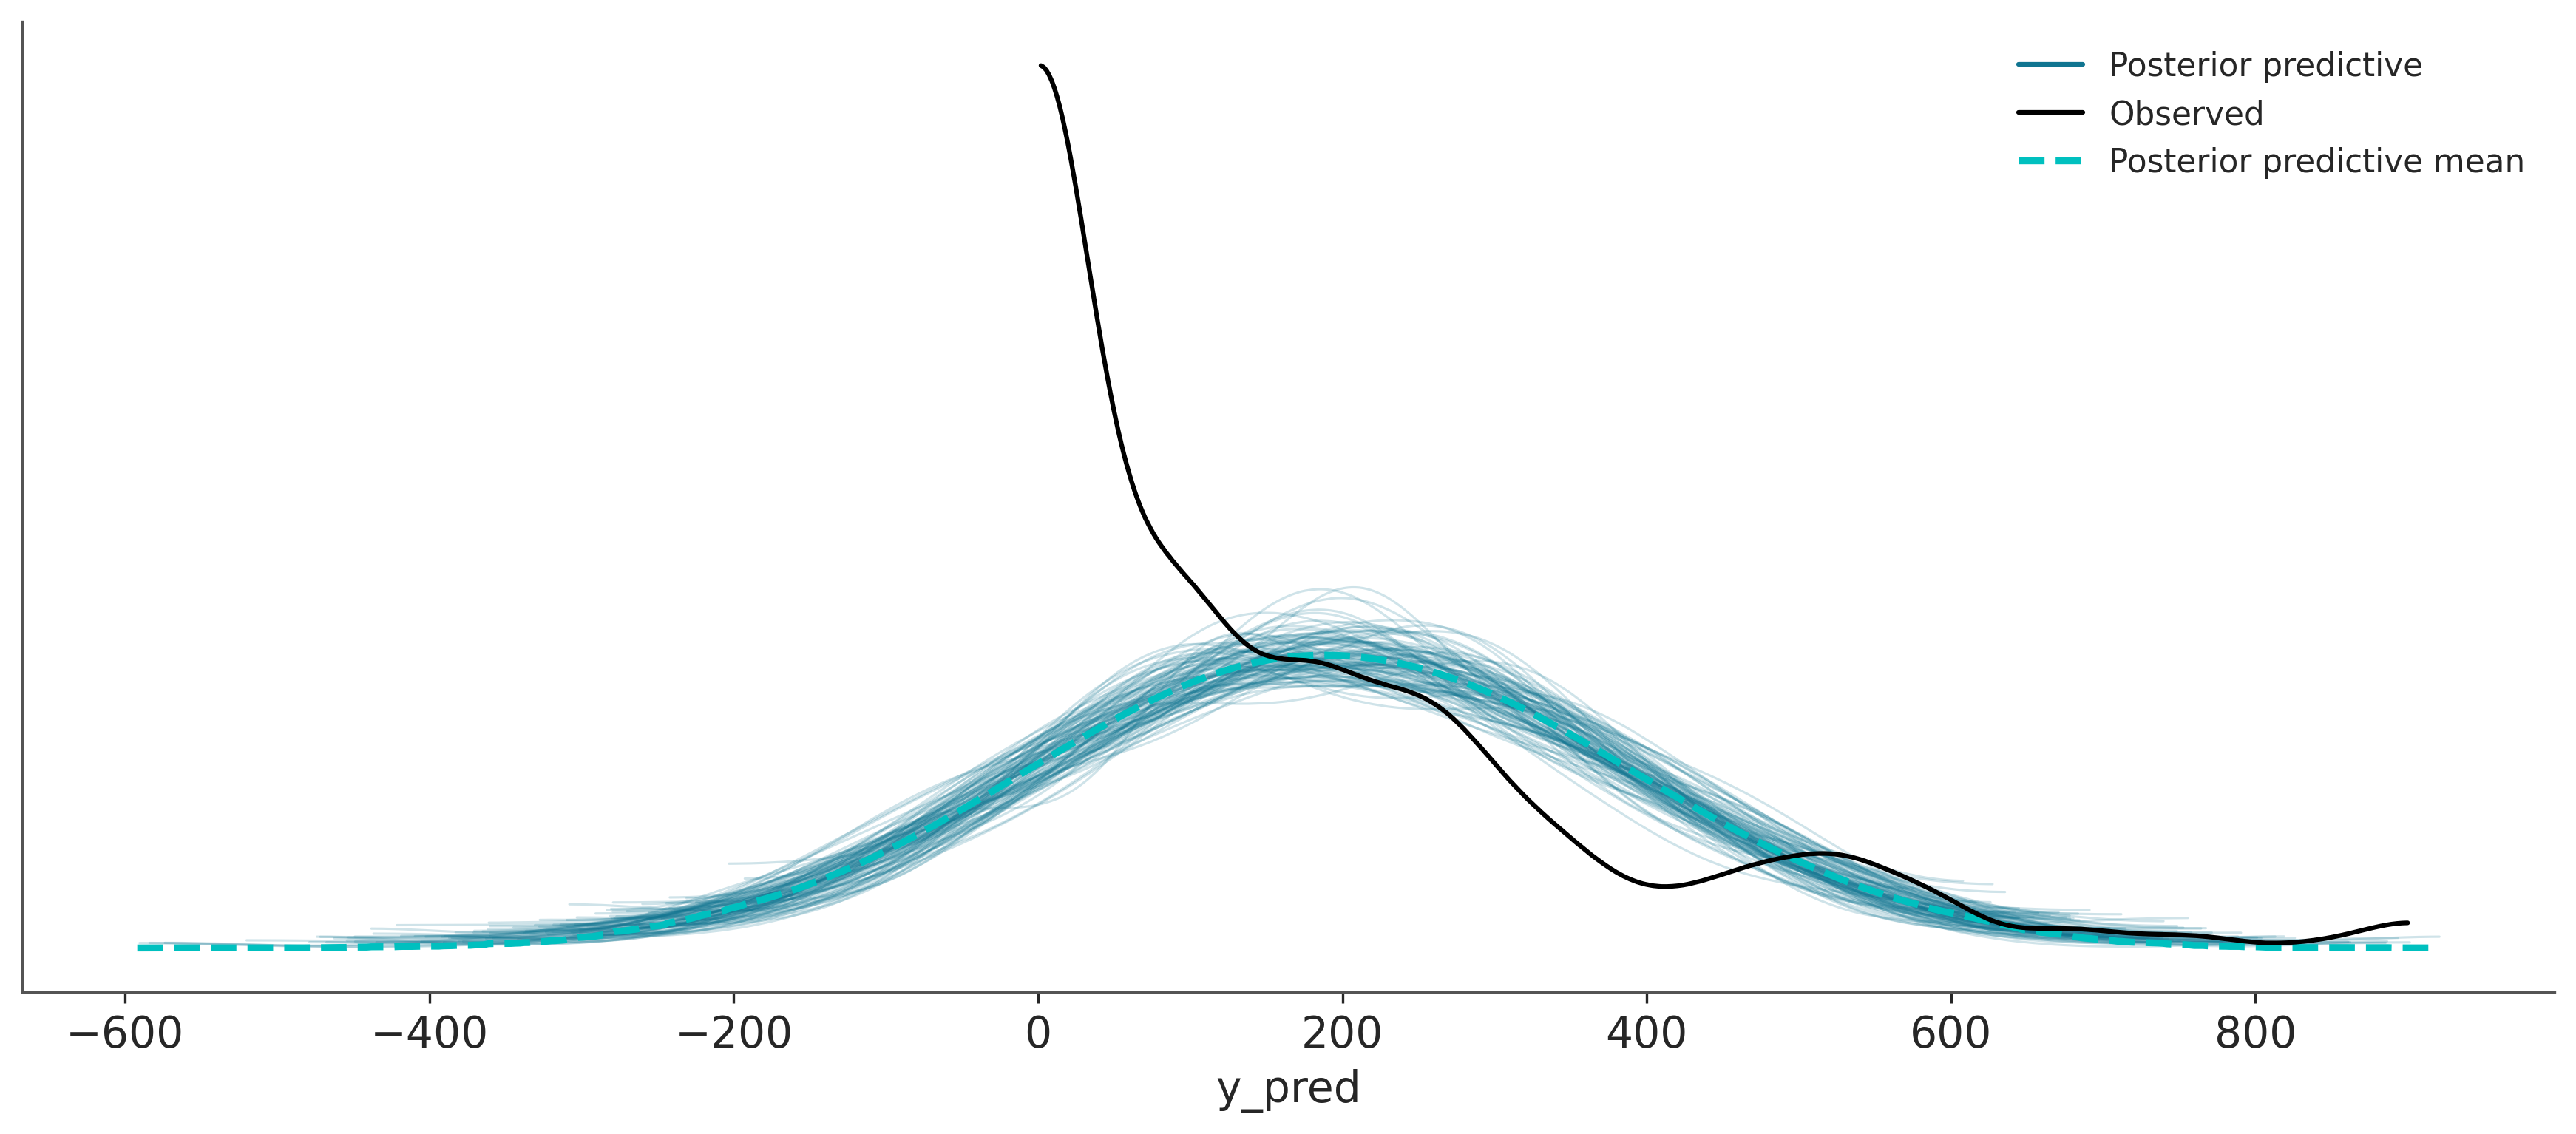

In [ ]:
az.plot_ppc(
    idata_bl,
    num_pp_samples=100
);

plt.show()

La diferencia conceptual es importante:

$$ \boxed{\text{Media posterior} \neq \text{Predicción posterior}} $$

La media posterior representa nuestra incertidumbre sobre el valor esperado.

La predictiva posterior incorpora además la variabilidad de una nueva observación.

## **Una primera dificultad del modelo**

Hay un problema evidente.

La variable alquiladas representa una cantidad de bicicletas, por lo que no puede tomar valores negativos.

Sin embargo, la distribución Normal permite:

$$ Y<0. $$

Por lo tanto, aunque el modelo lineal sea una buena primera aproximación, la distribución elegida para \(Y\) no necesariamente es la más adecuada.

Esto nos lleva a una idea más general:

No solo debemos pensar qué relación existe entre las variables. También debemos elegir una distribución para la variable respuesta que sea coherente con los datos.

## **Del modelo lineal al GLM**

El modelo lineal puede generalizarse permitiendo utilizar distintas distribuciones para \(Y\).

La idea general es:

$$ g(\mu_i)=\alpha+\beta X_i, $$

donde \(g\) es una función de enlace.

De esta manera, la parte lineal del modelo sigue siendo:

$$ \alpha+\beta X_i, $$

pero podemos utilizar distribuciones diferentes de la Normal.

| Tipo de dato    | Posible likelihood          |
| --------------- | --------------------------- |
| Continuo        | Normal                      |
| Conteos         | Poisson / Negativa Binomial |
| Proporciones    | Binomial                    |
| Tiempo positivo | Gamma                       |


## **Conteos: Negativa Binomial**

La cantidad de bicicletas alquiladas es un dato de conteo:

$$ Y_i=0,1,2,\ldots $$

Una posibilidad es utilizar una distribución Negativa Binomial.

En este caso podemos plantear:

$$ Y_i\sim\operatorname{NegBin}(\mu_i,\phi) $$

y utilizar un enlace logarítmico:

$$ \log(\mu_i)=\alpha+\beta X_i. $$

Equivalentemente:

$$ \mu_i=e^{\alpha+\beta X_i}. $$

La exponencial garantiza que \(\mu_i\) sea siempre positiva.


In [ ]:
with pm.Model() as modelo_nb:

    alpha = pm.Normal("alpha", mu=0, sigma=10)

    beta = pm.Normal("beta", mu=0, sigma=2)

    phi = pm.Exponential("phi", 1)

    mu = pm.math.exp(
        alpha + beta * bicis.temperatura
    )

    y_pred = pm.NegativeBinomial(
        "y_pred",
        mu=mu,
        alpha=phi,
        observed=bicis.alquiladas
    )

    idata_nb = pm.sample(
        random_seed=123
    )

Output()

Y obtenemos la predictiva posterior:

In [ ]:
with modelo_nb:
    pm.sample_posterior_predictive(
        idata_nb,
        extend_inferencedata=True,
        random_seed=123
    )

Output()

## **Comparamos las predicciones**

Podemos comparar visualmente ambos modelos mediante PPC:

/tmp/ipykernel_4710/3590788448.py:22: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


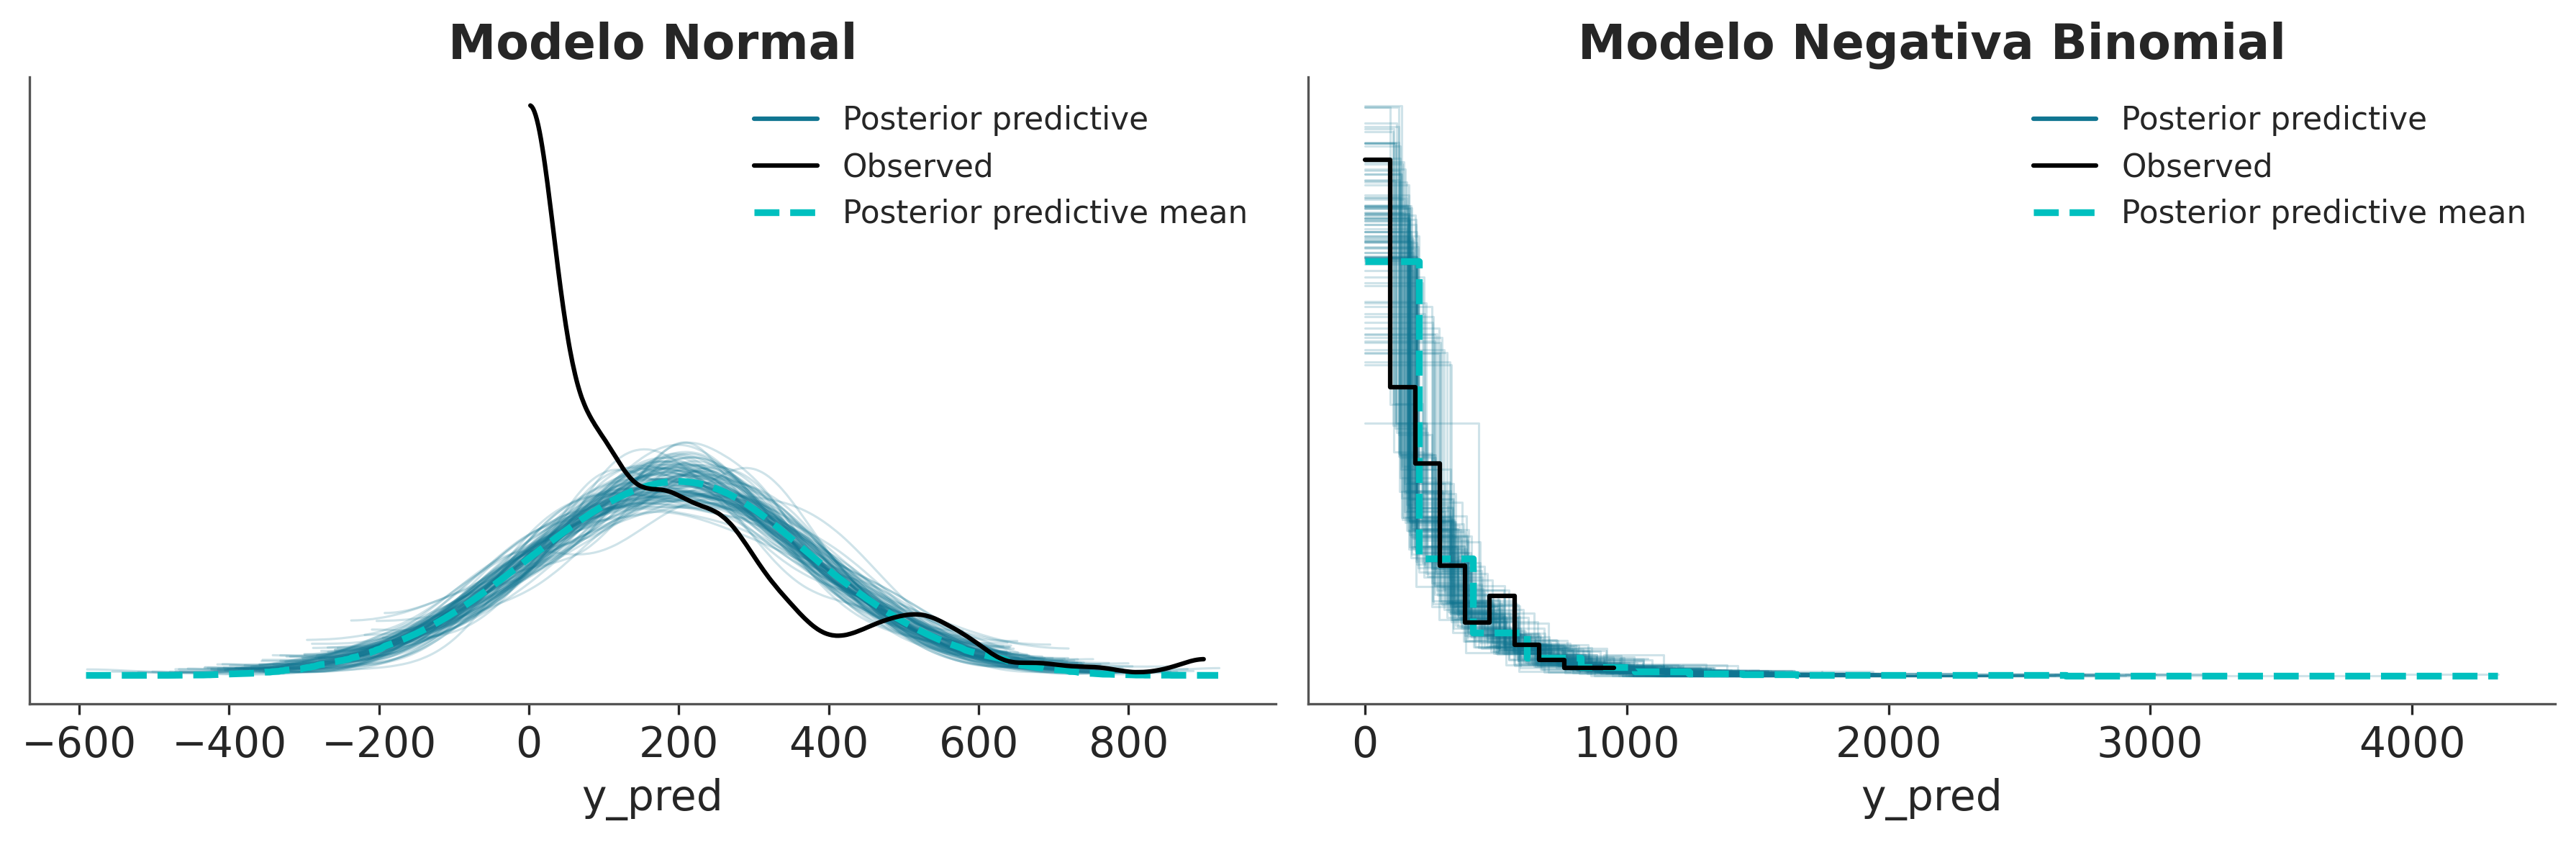

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

az.plot_ppc(
    idata_bl,
    num_pp_samples=100,
    ax=axes[0]
)

axes[0].set_title("Modelo Normal")

az.plot_ppc(
    idata_nb,
    num_pp_samples=100,
    ax=axes[1]
)

axes[1].set_title("Modelo Negativa Binomial")

plt.tight_layout()
plt.show()

La pregunta ahora no es simplemente ¿Qué modelo tiene una recta más linda?, sino ***¿Qué modelo genera datos compatibles con las características que observamos?***

En este ejemplo, la Negativa Binomial resulta más apropiada porque permite trabajar naturalmente con datos de conteo y evita predicciones negativas.



<font color="pink"> $$ \boxed{ \text{Modelo lineal} \rightarrow \text{Distribuciones posteriores} \rightarrow \text{Predicciones} \rightarrow \text{PPC} \rightarrow \text{GLM} } $$

La idea fundamental es que en un modelo bayesiano no obtenemos solamente una estimación puntual. Obtenemos distribuciones que nos permiten representar:

* incertidumbre sobre los parámetros;
* incertidumbre sobre la relación entre las variables;
* incertidumbre sobre futuras observaciones.

Y, al pasar a los GLM, podemos adaptar la distribución de la respuesta al tipo de datos que estamos modelando. Esto conecta directamente el modelo estadístico con la naturaleza del problema.

**Actividad:**

**Dar un breve texto descriptivo de la comparación realizada de ambos modelos anteriores (normal y binomial negativa).**

# **Casos particulares de GLM**


## 1. Regresión logística

La regresión logística es una extensión de la regresión lineal que se utiliza cuando la variable respuesta es binaria, es decir, cuando solo puede tomar dos valores, por ejemplo $Y\in{0,1}$.

En una regresión lineal, modelamos directamente el valor esperado de la variable respuesta mediante una combinación lineal de las variables explicativas:


$$Y=\alpha+\beta X+\varepsilon.$$


Sin embargo, este planteo no resulta adecuado cuando la variable respuesta es binaria. El problema es que una combinación lineal puede tomar cualquier valor real, mientras que lo que queremos modelar es una probabilidad, que necesariamente debe estar entre 0 y 1.

La regresión logística resuelve este problema mediante dos modificaciones principales:

utilizamos una función de enlace
$$g(p)=log(\frac{p}{1-p})$$

que transforma la combinación lineal en un valor entre 0 y 1;
modelamos la variable respuesta mediante una distribución Bernoulli —o, en el caso de datos agrupados, una distribución Binomial— en lugar de una distribución Gaussiana.

## 2. La función logística

La primera modificación consiste en utilizar la función logística, también llamada función sigmoide, como función inversa de enlace:

$$\text{logistica}(z)= g^{-1}(z)=\frac{1}{1+e^{-z}}$$


Esta función tiene una propiedad fundamental: para cualquier valor real de (z), el resultado se encuentra siempre entre 0 y 1.

Por ejemplo:

* si z es un número muy negativo, la función logística se aproxima a 0;
* si z=0, la función vale 0.5;
* si z es un número muy positivo, la función se aproxima a 1.

Por lo tanto, podemos partir de una combinación lineal


$$z=\alpha+\beta X$$


y transformarla en una probabilidad:

$$\operatorname{logística}(\alpha+\beta X)$$


De esta manera, aunque $\alpha+\beta X$ pueda tomar cualquier valor real, $\theta$ siempre será una cantidad válida como probabilidad.

La forma de la función explica por qué también se la conoce como sigmoide: presenta una forma característica de $S$.

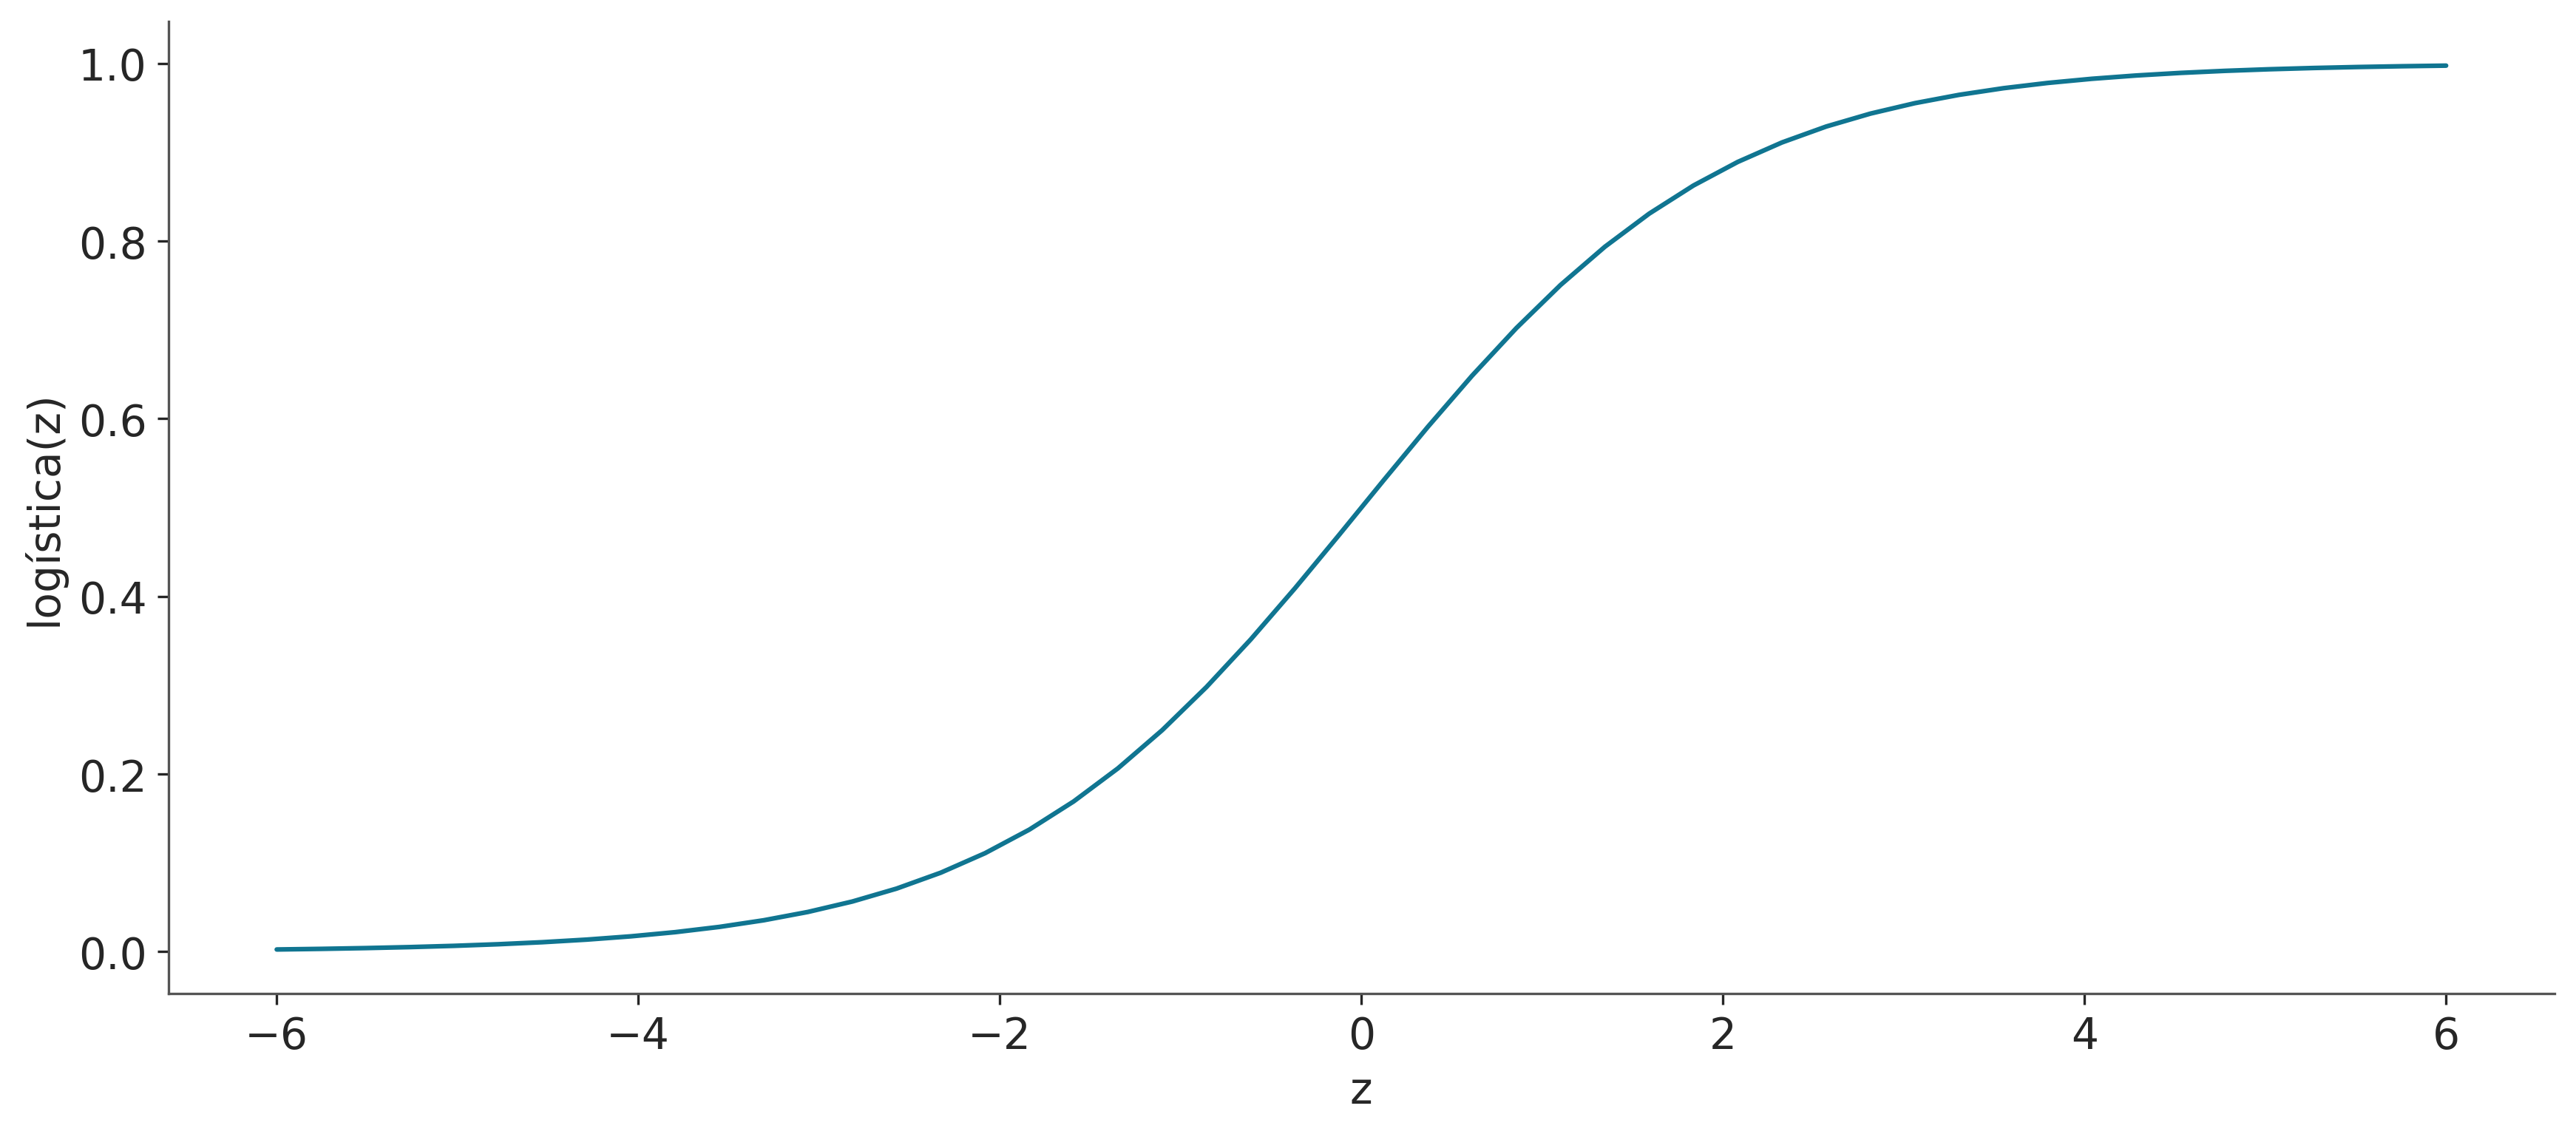

In [ ]:
z = np.linspace(-6, 6)
logística = 1 / (1 + np.exp(-z))
plt.plot(z, logística)
plt.xlabel('z')
plt.ylabel('logística(z)');

## 3. La distribución de la variable respuesta

El segundo paso consiste en modificar la distribución utilizada para modelar la variable respuesta.

Si nuestros datos son binarios,

$$
Y\in\{0,1\},
$$

tiene sentido utilizar una distribución **Bernoulli**. Esta distribución describe un único ensayo con dos posibles resultados y está parametrizada por una probabilidad $\theta$:

$$
Y\sim\operatorname{Bernoulli}(\theta).
$$

Por ejemplo, si $Y=1$ representa que una determinada observación pertenece a una clase y $Y=0$ que no pertenece a ella, entonces $\theta$ representa la probabilidad de obtener $Y=1$.

La regresión logística permite hacer que esa probabilidad dependa de las variables explicativas.

El modelo queda entonces:

$$
\theta
=
\operatorname{logística}(\alpha+\beta X),
$$

$$
Y\sim\operatorname{Bernoulli}(\theta).
$$

O, de manera equivalente,

$$
Y\sim
\operatorname{Bernoulli}
\left(
\operatorname{logística}(\alpha+\beta X)
\right).
$$

La idea central es que **no modelamos directamente la variable binaria mediante una recta**. Lo que hacemos es modelar una cantidad intermedia, $\alpha+\beta X$, y luego transformarla mediante la función logística para obtener una probabilidad.


## 4. ¿Qué significa el modelo?

Supongamos que queremos predecir si una observación pertenece a una determinada categoría.

El modelo calcula primero:

$$
z=\alpha+\beta X.
$$

Este valor \(z\) puede ser cualquier número real. Luego aplicamos la función logística:

$$
\theta=\frac{1}{1+e^{-z}}.
$$

El resultado es una probabilidad:

$$
0\leq\theta\leq1.
$$

Finalmente, utilizamos esa probabilidad para modelar la variable binaria:

$$
Y\sim\operatorname{Bernoulli}(\theta).
$$

Por ejemplo, si para una determinada observación obtenemos

$$
\theta=0.8,
$$

el modelo está indicando que, dadas las variables explicativas, la probabilidad de que \(Y=1\) es 0.8.

Es importante notar que la regresión logística **no necesita convertir inmediatamente la probabilidad en una clase**. Primero produce una probabilidad y, si queremos clasificar las observaciones, podemos posteriormente establecer un umbral. Por ejemplo, utilizando \(0.5\):

$$
\hat Y=
\begin{cases}
1 & \text{si } \theta\geq0.5,\\
0 & \text{si } \theta<0.5.
\end{cases}
$$

El umbral, sin embargo, es una decisión adicional y no forma parte de la definición probabilística del modelo.


## 5. Interpretación mediante el logit

La función logística también puede escribirse utilizando su función inversa, denominada **logit**:

$$
\operatorname{logit}(\theta)
=
\log\left(\frac{\theta}{1-\theta}\right).
$$

De esta forma, el modelo puede expresarse como:

$$
\operatorname{logit}(\theta)
=
\alpha+\beta X.
$$

Esto permite interpretar la regresión logística como un modelo lineal sobre la escala del **logaritmo de los odds**.

En particular, $\beta$ indica cómo cambia el logit de la probabilidad cuando $X$ aumenta una unidad, manteniendo constantes las demás variables del modelo.

Por ejemplo, si $\beta>0$, un aumento de $X$ se asocia con un aumento de la probabilidad de $Y=1$; si $\beta<0$, se asocia con una disminución de dicha probabilidad.

# 6. Regresión logística aplicada al conjunto de datos Iris

Ahora vamos a aplicar una regresión logística al conocido conjunto de datos **Iris**.

El conjunto de datos Iris contiene información sobre **150 flores**, pertenecientes a tres especies:

* *Iris setosa*,
* *Iris versicolor*,
* *Iris virginica*.

Hay 50 observaciones de cada especie.

Para cada flor contamos con cuatro variables que describen sus características morfológicas:

* largo del sépalo (*sepal_length*);
* ancho del sépalo (*sepal_width*);
* largo del pétalo (*petal_length*);
* ancho del pétalo (*petal_width*).

Los **sépalos** son estructuras que forman parte de la flor y que, entre otras funciones, protegen el botón floral durante su desarrollo.

En este caso, las cuatro medidas serán nuestras **variables explicativas**, mientras que la especie será la **variable respuesta** que queremos predecir.

Sin embargo, aquí aparece una diferencia importante respecto del ejemplo anterior: la variable respuesta tiene **tres categorías**, no dos.

La regresión logística binaria que acabamos de introducir está diseñada para respuestas con dos categorías. Por lo tanto, para utilizarla sobre Iris podemos, por ejemplo, plantear un problema binario:

$$
Y=
\begin{cases}
1 & \text{si la flor es virginica},\\
0 & \text{si la flor no es virginica}.
\end{cases}
$$

Ahora sí tenemos una variable respuesta binaria y podemos utilizar una regresión logística.

El modelo tendrá la forma:

$$
\operatorname{logit}(\theta_i)
=
\alpha
+
\beta_1\,\text{sepal_length}_i
+
\beta_2\,\text{sepal_width}_i
+
\beta_3\,\text{petal_length}_i
+
\beta_4\,\text{petal_width}_i.
$$

Equivalentemente,

$$
\theta_i
=
\operatorname{logística}
\left(
\alpha
+
\beta_1\,\text{sepal_length}_i
+
\beta_2\,\text{sepal_width}_i
+
\beta_3\,\text{petal_length}_i
+
\beta_4\,\text{petal_width}_i
\right),
$$

y

$$
Y_i\sim\operatorname{Bernoulli}(\theta_i).
$$

Así, para cada flor, el modelo utiliza sus cuatro características para estimar la probabilidad de que pertenezca a la clase *virginica*.

A continuación podemos ajustar este modelo a los datos y observar cómo las diferentes características de las flores contribuyen a distinguir entre las clases.


In [ ]:
iris = pd.read_csv('iris.csv')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Pensemos en solo dos de las clases, *setosa y versicolor*, y solo una variable predictora que va a ser la *longitud del sépalo*.

In [ ]:
# Seleccionamos únicamente las especies setosa y versicolor
df = iris.query("species == ('setosa', 'versicolor')")

# Codificamos las especies como 0 y 1
y_0 = pd.Categorical(df['species']).codes

# Seleccionamos la variable explicativa
x_n = 'sepal_length'

# Extraemos los valores de longitud del sépalo
x_0 = df[x_n].values

# Centramos la variable restando su media
x_c = x_0 - x_0.mean()

### Construcción del modelo en PyMC

Al igual que en otros modelos de regresión, centrar las variables explicativas puede ayudar a mejorar el muestreo y la interpretación del modelo. En este caso, podemos restar a cada variable su media, de modo que trabajemos con variables centradas alrededor de cero.

Una vez que los datos están preparados en el formato adecuado, podemos construir el modelo logístico utilizando PyMC.

La primera parte del modelo resulta familiar si ya trabajamos con regresión lineal. Definimos una combinación lineal de las variables explicativas:

$$
\mu=\alpha+\beta X.
$$

La diferencia aparece al momento de transformar esta cantidad para obtener una probabilidad. Aplicamos la función logística:

$$
\theta=\operatorname{logística}(\mu).
$$

En PyMC, en lugar de escribir explícitamente la función logística,

$$
\frac{1}{1+e^{-\mu}},
$$

utilizamos `pm.math.sigmoid(mu)`. Esta función transforma cualquier valor real de $\mu$ en un valor entre 0 y 1, que podemos interpretar como la probabilidad de que la observación pertenezca a la clase $Y=1$.

En el modelo, $θ$ es entonces una variable determinista: no es un parámetro que muestreamos directamente, sino una cantidad que se obtiene a partir de los parámetros del modelo y de las variables explicativas.

También definimos `bd`, que representa el límite de decisión. Este valor nos permitirá visualizar posteriormente el punto a partir del cual el modelo asigna una observación a una de las dos clases.

Finalmente, la probabilidad $\theta$ se utiliza como parámetro de la distribución Bernoulli que modela la variable respuesta:

$$
Y_i\sim\operatorname{Bernoulli}(\theta_i).
$$

De esta manera, el modelo combina una estructura lineal, como en la regresión tradicional, con una transformación logística que permite trabajar con una variable respuesta binaria.

In [ ]:
with pm.Model() as modelo_rl:
    α = pm.Normal('α', mu=0, sigma=1)
    β = pm.Normal('β', mu=0, sigma=5)

    μ = α + β * x_c
    θ = pm.Deterministic('θ', pm.math.sigmoid(μ))
    bd = pm.Deterministic('bd', -α/β)

    yl = pm.Bernoulli('yl', p=θ, observed=y_0)

    idata_rl = pm.sample(random_seed=123)

Output()

In [ ]:
az.summary(idata_rl, var_names='~θ')

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
bd,-0.052,0.062,-0.164,0.066,0.001,0.002,1820.0,1132.0,1.0
α,0.272,0.318,-0.313,0.874,0.007,0.008,1768.0,1333.0,1.0
β,5.172,1.013,3.355,7.211,0.027,0.027,1518.0,922.0,1.0


Ahora vamos a graficar los datos junto con la curva sigmoide ajustada:

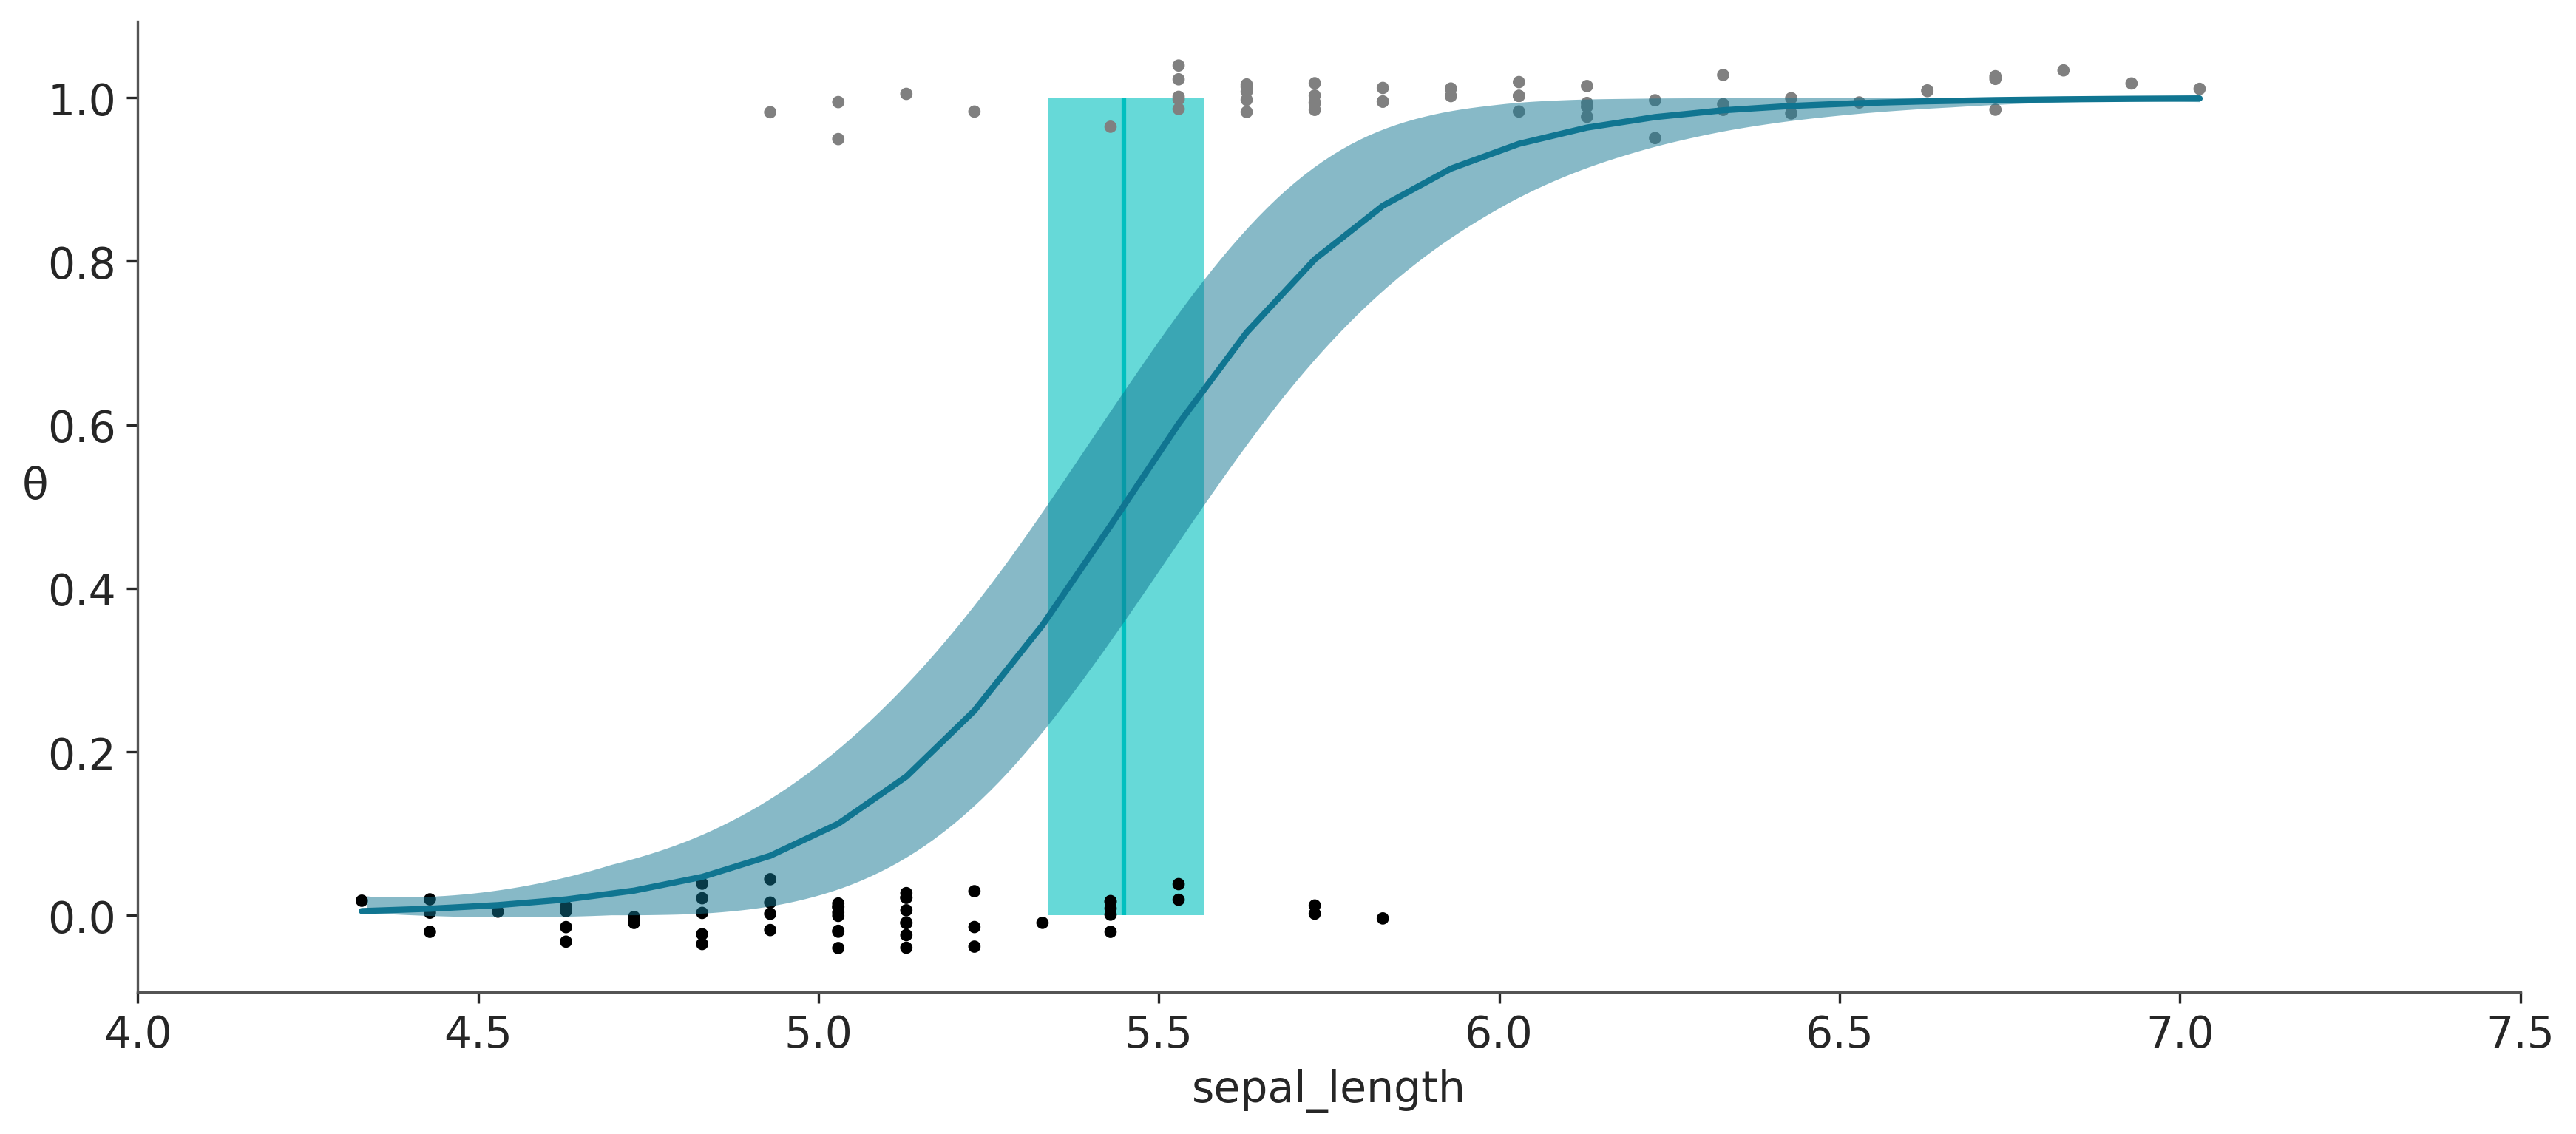

In [ ]:
# Extraemos las muestras de la distribución posterior
posterior = idata_rl.posterior

# Calculamos la probabilidad media para cada valor de x
theta = posterior["θ"].mean(("chain", "draw"))

# Ordenamos los valores de x para graficar la curva correctamente
idx = np.argsort(x_c)

# Creamos la figura y el eje
_, ax = plt.subplots()

# Graficamos la probabilidad media estimada
ax.plot(x_c[idx], theta[idx], color='C0', lw=2)

# Marcamos la frontera de decisión media
ax.vlines(posterior['bd'].mean(("chain", "draw")), 0, 1, color='C1', zorder=0)

# Calculamos el intervalo HDI de la frontera de decisión
bd_hdi = az.hdi(posterior['bd'])

# Representamos el intervalo HDI de la frontera de decisión
ax.fill_betweenx([0, 1], bd_hdi["bd"][0], bd_hdi["bd"][1], color='C1', alpha=0.6, lw=0)

# Mostramos los datos observados con un pequeño desplazamiento vertical
ax.scatter(x_c, np.random.normal(y_0, 0.02), marker='.', color=[f'{0.5*x}' for x in y_0])

# Representamos el intervalo de credibilidad de la probabilidad estimada
az.plot_hdi(x_c, posterior['θ'], color='C0', ax=ax, fill_kwargs={"lw": 0})

# Etiqueta del eje horizontal
ax.set_xlabel(x_n)

# Etiqueta del eje vertical
ax.set_ylabel('θ', rotation=0)

# Usamos la escala original de la variable para las etiquetas del eje x
locs, _ = plt.xticks()
ax.set_xticks(locs, np.round(locs + x_0.mean(), 1));

 Una vez ajustado el modelo, podemos visualizar la relación entre una de las variables explicativas y la probabilidad estimada por el modelo.

En este ejemplo utilizamos la longitud del sépalo y consideramos únicamente dos especies del conjunto Iris:

$$
\text{setosa}=0,
\qquad
\text{versicolor}=1.
$$

De esta forma, transformamos el problema original en una clasificación binaria.

Los puntos del gráfico representan las observaciones disponibles. Como la variable respuesta solo puede tomar los valores 0 y 1, todos los puntos se ubicarían exactamente sobre esas dos líneas. Para facilitar la visualización y evitar que los puntos queden completamente superpuestos, agregamos una pequeña cantidad de ruido visual, denominado ***jitter***, únicamente sobre el eje correspondiente a la variable respuesta.

Sobre los datos observamos la curva característica de la regresión logística. La línea central representa el valor medio de $\theta$ estimado por el modelo para cada valor de la longitud del sépalo.

Esta curva puede interpretarse como:

$$
P(Y=1\mid X),
$$

es decir, la probabilidad estimada de que una flor pertenezca a la clase versicolor dado su valor de longitud del sépalo.

Cuando la curva toma valores cercanos a 0, el modelo asigna una baja probabilidad de pertenecer a la clase versicolor. A medida que la longitud del sépalo cambia, esta probabilidad puede aumentar hasta acercarse a 1.

La forma de $S$ aparece justamente porque estamos aplicando la función logística a la combinación lineal de las variables.

La banda semitransparente alrededor de la curva representa el HDI del 94 % de la distribución posterior de $\theta$. Por lo tanto, no estamos mostrando únicamente una curva estimada, sino también la incertidumbre asociada a esa estimación.

Esto es particularmente importante desde el punto de vista bayesiano: para cada valor de la variable explicativa no obtenemos solamente una probabilidad puntual, sino una distribución posterior de posibles valores de esa probabilidad.

El gráfico nos permite entonces observar simultáneamente:

los datos observados;
la probabilidad estimada por el modelo;
la incertidumbre asociada a esa probabilidad;
y, posteriormente, el límite de decisión utilizado para transformar probabilidades en clases.

## Varianza variable

Hasta ahora, cuando utilizamos un modelo lineal, nos concentramos principalmente en describir cómo cambia la **media** de la variable respuesta en función de una o más variables explicativas.

Por ejemplo, podemos plantear:

$$
Y_i\sim\mathcal{N}(\mu_i,\sigma^2),
$$

donde la media depende de las variables explicativas:

$$
\mu_i=\alpha+\beta X_i.
$$

En este planteo estamos suponiendo que la varianza \(\sigma^2\) es la misma para todas las observaciones. Es decir, independientemente del valor de \(X\), asumimos que los datos presentan aproximadamente el mismo nivel de dispersión alrededor de la media.

Este supuesto puede ser razonable en algunas situaciones, pero no siempre describe adecuadamente los datos. En particular, podemos encontrarnos con situaciones en las que la variabilidad **cambia sistemáticamente a medida que cambia la variable explicativa**.

En esos casos, no alcanza con modelar únicamente la media. También podemos construir un modelo para la **varianza**, permitiendo que su valor dependa de las variables explicativas.

Una forma sencilla de hacerlo consiste en plantear dos componentes dentro del modelo:

$$
\mu_i=\alpha+\beta X_i
$$

para describir cómo cambia la media, y

$$
\sigma_i=f(X_i)
$$

para describir cómo cambia la dispersión.

De esta manera, el modelo deja de asumir una única varianza común para todas las observaciones y permite representar situaciones en las que algunas regiones de los datos son más variables que otras.

Esto resulta especialmente útil cuando observamos una estructura como la siguiente: para determinados valores de \(X\), las observaciones se encuentran muy concentradas alrededor de la media, mientras que para otros valores presentan una dispersión mucho mayor.



### Un ejemplo: crecimiento infantil

Para ilustrar esta idea vamos a trabajar con datos relacionados con el **crecimiento infantil**.

El crecimiento durante los primeros meses de vida presenta una relación clara con la edad. Por lo tanto, podemos utilizar la edad como variable explicativa y la longitud de las niñas como variable respuesta.

Este tipo de información resulta de gran importancia en el ámbito de la salud pública. Los datos de crecimiento infantil permiten estudiar cómo se distribuyen determinadas medidas antropométricas en una población y construir referencias que pueden utilizarse para evaluar el desarrollo durante los primeros años de vida.

En nuestro ejemplo contamos con observaciones de **longitud de niñas en función de su edad, medida en meses**.

Podemos comenzar planteando un modelo lineal para la media:

$$
\mu_i=\alpha+\beta X_i,
$$

donde $X_i$ representa la edad y $\mu_i$ la longitud media esperada para esa edad.

Pero además de preguntarnos **cómo cambia la longitud promedio con la edad**, podemos preguntarnos:

> **¿La variabilidad de las longitudes también se mantiene constante a lo largo de las distintas edades?**

Esta segunda pregunta es la que nos llevará a considerar un modelo con **varianza variable**.

En este caso plantearemos $$f(X_i)=\gamma +\delta X_i$$


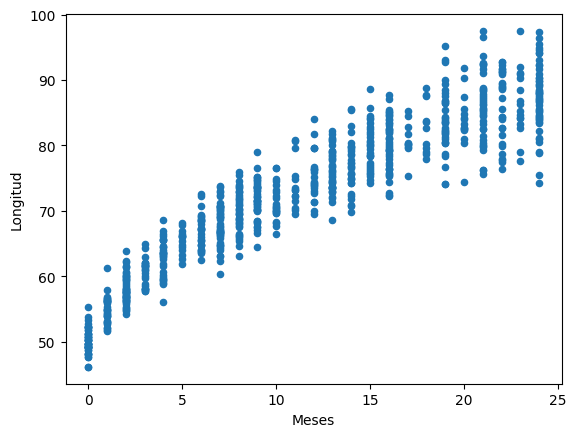

In [ ]:
datos = pd.read_csv('babies.csv')

datos.plot.scatter('Meses', 'Longitud');

Para este modelo incorporamos algunas modificaciones respecto de la regresión lineal anterior:

* La **media** de la respuesta se modela en función de $\sqrt{x}$, lo que permite representar una relación curva entre la edad y la longitud.
* La **variabilidad** ya no se considera constante: la desviación estándar $\sigma$ también depende de $x$. Para modelarla introducimos los parámetros $\gamma$ y $\delta$, que determinan su nivel y cómo cambia con la edad.
* Utilizamos `x_shared` para almacenar la variable explicativa. Esto permite posteriormente modificar los valores de $x$ y generar nuevas predicciones sin tener que volver a ajustar el modelo.


<font color="red"> LEER (como tarea para la casa):


En la figura siguiente podemos observar tanto la tendencia central como la variabilidad estimada por el modelo. La **curva negra** representa la media posterior de $\mu$, mientras que las **bandas** muestran la dispersión alrededor de esa media: la banda más estrecha corresponde a una desviación estándar y la más amplia, a dos.

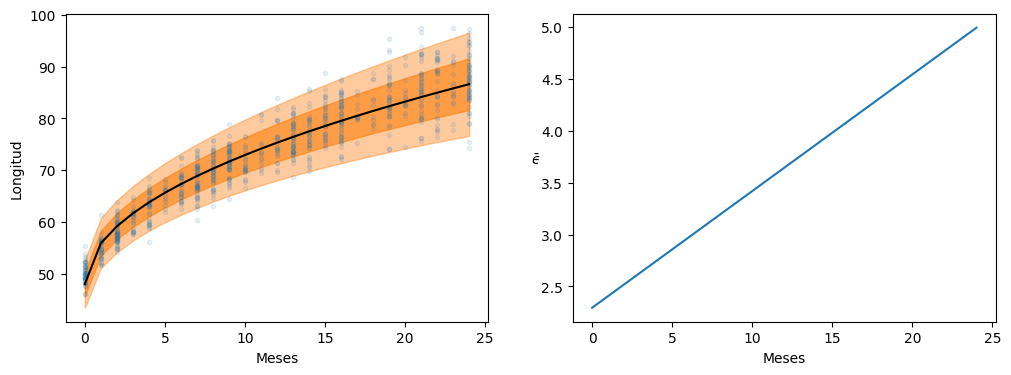

In [ ]:
# Creamos una figura con dos gráficos para visualizar la media y la variabilidad
_, axes = plt.subplots(1, 2, figsize=(12, 4))

# Graficamos los datos observados: edad en meses vs. longitud
axes[0].plot(datos.Meses, datos.Longitud, 'C0.', alpha=0.1);

# Extraemos las muestras posteriores del modelo
posterior = az.extract(idata_vv)

# Calculamos la media posterior de μ para cada edad
μ_m = posterior['μ'].mean("sample").values

# Calculamos la media posterior de σ para cada edad
σ_m = posterior['σ'].mean("sample").values

# Graficamos la media estimada de la longitud
axes[0].plot(datos.Meses, μ_m, c='k')

# Mostramos una banda de una desviación estándar alrededor de la media
axes[0].fill_between(datos.Meses, μ_m + 1 * σ_m, μ_m - 1 * σ_m, alpha=0.6, color='C1')

# Mostramos una banda de dos desviaciones estándar alrededor de la media
axes[0].fill_between(datos.Meses, μ_m + 2 * σ_m, μ_m - 2 * σ_m, alpha=0.4, color='C1')

axes[0].set_xlabel('Meses')

axes[0].set_ylabel('Longitud');


# Graficamos cómo cambia la desviación estándar σ con la edad
axes[1].plot(datos.Meses, σ_m)

axes[1].set_xlabel('Meses');
axes[1].set_ylabel(r'$\bar ϵ$', rotation=0);

<font color="red"> Actividad:

plantear el modelo trabajando con otra transformación (distinta a $\sqrt(X)$ y comparar modelos. ¿Con cuál se queda y por qué?

## Regresión lineal jerárquica


En este ejemplo, vamos a explorar cómo podemos aplicar el mismo concepto de jerarquización a modelos de regresión lineal,  para realizar inferencias a nivel de subgrupo y a nivel global.

Vamos a trabajar con un ejemplo práctico incluyendo hiperparámetros y determinando sus hiperpriors:

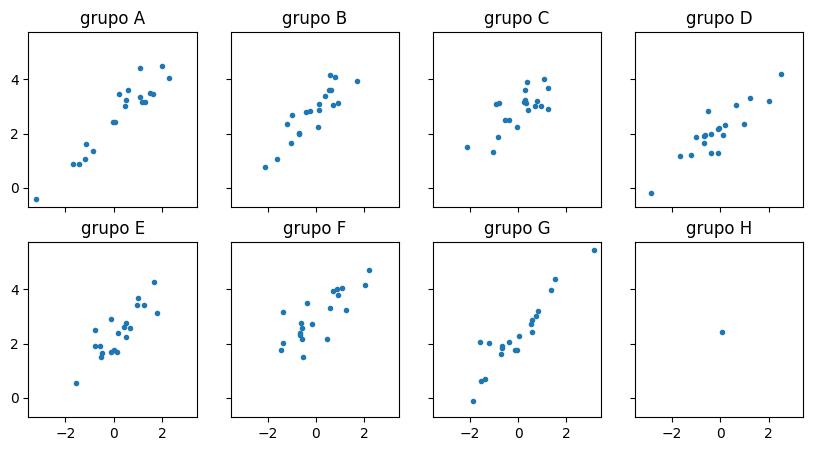

In [ ]:
N = 20
# Cantidad de observaciones que tendrá cada grupo.

grupos = ["A", "B", "C", "D", "E", "F", "G", "H"]
# Definimos los 8 grupos que vamos a simular.

M = len(grupos)
# M es la cantidad total de grupos. En este caso, M = 8.


idx = np.repeat(range(M - 1), N)

idx = np.append(idx, 7)

np.random.seed(314)

alpha_real = np.random.normal(2.5, 0.5, size=M)

beta_real = np.random.beta(6, 1, size=M)

eps_real = np.random.normal(0, 0.5, size=len(idx))

y_m = np.zeros(len(idx))


x_m = np.random.normal(0, 1, len(idx))

y_m = alpha_real[idx] + beta_real[idx] * x_m + eps_real

_, ax = plt.subplots(2, 4, figsize=(10, 5), sharex=True, sharey=True)

ax = np.ravel(ax)
j, k = 0, N

for i, g in enumerate(grupos):

    ax[i].scatter(x_m[j:k], y_m[j:k], marker=".")

    ax[i].set_title(f"grupo {g}")

    j += N

    k += N


### **1. Construcción del modelo jerárquico:**

In [ ]:
coords = {"grupo": grupos}

with pm.Model(coords=coords) as modelo_jerárquico:

    # -------------------------
    # Hiper-priors
    # -------------------------

    α_μ = pm.Normal("α_μ", mu=y_m.mean(), sigma=1)

    α_σ = pm.HalfNormal("α_σ", 5)

    β_μ = pm.Normal("β_μ", mu=0, sigma=1)

    β_σ = pm.HalfNormal("β_σ", sigma=5)

    # -------------------------
    # Priors de los parámetros
    # -------------------------

    α = pm.Normal("α", mu=α_μ, sigma=α_σ, dims="grupo")

    β = pm.Normal("β", mu=β_μ, sigma=β_σ, dims="grupo")

    σ = pm.HalfNormal("σ", 5)

    _ = pm.Normal(
        "y_pred",
        mu=α[idx] + β[idx] * x_m,
        sigma=σ,
        observed=y_m
    )

    idata_mj = pm.sample(random_seed=123)


Output()

ERROR:pymc.stats.convergence:There were 95 divergences after tuning. Increase `target_accept` or reparameterize.


**¡Observamos que hay divergencias! ¿Cómo las tratamos?**

Al ejecutar el modelo jerárquico, PyMC muestra una advertencia indicando que se detectaron **divergencias** durante el muestreo. Esto significa que algunas de las muestras obtenidas pueden no representar adecuadamente la distribución posterior, por lo que debemos revisar el diagnóstico del modelo.

Una primera alternativa es aumentar `target_accept`, que por defecto vale `0.8`. Podemos probar con valores como `0.9` o `0.95`:


`idata_mj = pm.sample(target_accept=0.9, random_seed=123)`





Aumentar este valor puede reducir las divergencias, aunque también puede hacer que el muestreo sea más lento. En este ejemplo, veremos que incluso utilizando valores mayores las divergencias pueden persistir.

Cuando esto ocurre, una alternativa es **reparametrizar el modelo**. Reparametrizar significa expresar el mismo modelo de una forma matemáticamente equivalente, pero que resulte más conveniente para el muestreador.

En el modelo anterior, cada pendiente se definía directamente como:

$$
\beta_j \sim \mathcal{N}(\beta_\mu,\beta_\sigma)
$$

En la parametrización no centrada, en cambio, escribimos:

$$
\beta_j = \beta_\mu + \beta_{\text{offset},j}\,\beta_\sigma
$$

donde

$$
\beta_{\text{offset},j} \sim \mathcal{N}(0,1).
$$

De esta manera, `β_offset` representa cuánto se aleja la pendiente del grupo respecto de la media común `β_μ`, en unidades de `β_σ`.

La primera forma se conoce como **parametrización centrada**, mientras que la segunda se conoce como **parametrización no centrada**. Ambas representan el mismo modelo, pero la segunda puede facilitar el muestreo y ayudar a reducir las divergencias.

Veamos cómo implementarla en PyMC.


### **2. Construcción del modelo no jerárquico:**

In [ ]:
with pm.Model(coords=coords) as jerárquico_no_centrado:

    # -------------------------
    # Hiper-priors
    # -------------------------

    α_μ = pm.Normal("α_μ", mu=y_m.mean(), sigma=1)

    α_σ = pm.HalfNormal("α_σ", 5)

    β_μ = pm.Normal("β_μ", mu=0, sigma=1)

    β_σ = pm.HalfNormal("β_σ", sigma=5)

    # -------------------------
    # Priors
    # -------------------------

    α = pm.Normal("α", mu=α_μ, sigma=α_σ, dims="grupo")

    β_offset = pm.Normal("β_offset", mu=0, sigma=1, dims="grupo")

    β = pm.Deterministic("β", β_μ + β_offset * β_σ, dims="grupo")

    σ = pm.HalfNormal("σ", 5)

    _ = pm.Normal(
        "y_pred",
        mu=α[idx] + β[idx] * x_m,
        sigma=σ,
        observed=y_m
    )

    idata_ncen = pm.sample(target_accept=0.85, random_seed=123)


Output()

ERROR:pymc.stats.convergence:There were 3 divergences after tuning. Increase `target_accept` or reparameterize.


Observemos que al reparametrizar el modelo, las divergencias disminuyen porque también cambia la geometría de la distribución posterior.

En la parametrización centrada puede aparecer una **geometría de embudo**: cuando \(\beta_\sigma\) es pequeño, los valores posibles de las pendientes de los grupos quedan muy concentrados, mientras que para valores grandes la distribución se ensancha. Esta geometría dificulta el muestreo, ya que el algoritmo debe adaptarse simultáneamente a regiones con escalas muy diferentes.

La parametrización no centrada ayuda a separar estas dos fuentes de variabilidad y puede facilitar la exploración de la distribución posterior. Por eso, junto con un `target_accept` adecuado, suele reducir o eliminar las divergencias en modelos jerárquicos.


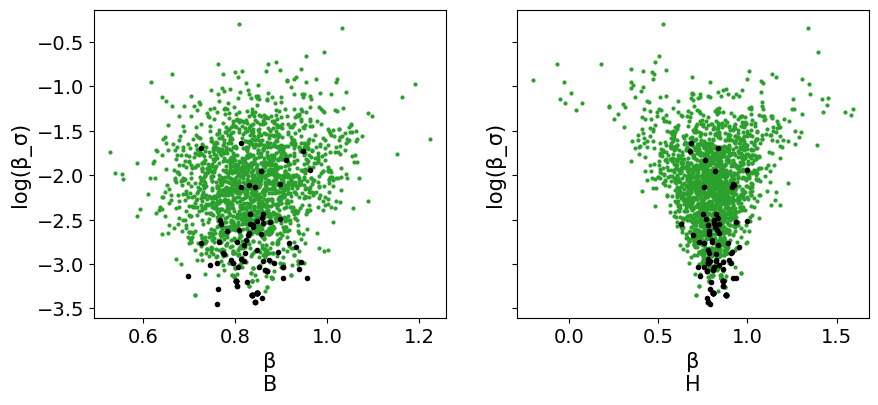

In [ ]:
idata_mj.posterior["log(β_σ)"] = np.log(idata_mj.posterior["β_σ"])

_, axes = plt.subplots(
    1, 2,
    sharey="row",
    sharex="col",
    figsize=(10, 4)
)

nvars = ["log(β_σ)", "log(β_σ)"]

glabel = ["B", "H"]

for ax, var, gl in zip(axes.ravel(), nvars, glabel):

    az.plot_pair(
        idata_mj,
        var_names=["β", var],
        coords={"grupo": [gl]},
        divergences=True,
        scatter_kwargs={"color": "C2"},
        divergences_kwargs={"color": "k", "marker": ".", "mec": None},
        ax=ax,
    )


¿Qué cambia al utilizar la parametrización no centrada?

En la primera fila de la figura vemos la relación entre $\log(\beta_\sigma)$ y $\beta_{\text{offset}}$, que es la variable que introdujimos con la reparametrización. La diferencia importante es que la forma de la distribución ya no presenta un embudo tan marcado: la región que debe explorar el sampler tiene una geometría mucho más regular.

¿Por qué esto es importante? Pensemos en el embudo de la parametrización centrada. Cuando $\beta_\sigma$ toma valores pequeños, las pendientes de los grupos quedan muy concentradas en una región muy estrecha. El sampler puede explorar correctamente la parte ancha del embudo, pero al acercarse a esa zona estrecha necesita adaptar mucho su trayectoria. Si no consigue hacerlo, aparecen divergencias y puede dejar sin explorar parte de la distribución.

En la parametrización no centrada, el sampler ya no necesita explorar directamente esa geometría. Trabaja con $\beta_{\text{offset}}$, que tiene una distribución estándar, y luego obtenemos \(\beta\) mediante:

$$
\beta = \beta_\mu + \beta_{\text{offset}}\beta_\sigma.
$$

Por eso, en la segunda fila podemos seguir viendo un embudo, e incluso puede parecer más pronunciado que antes. **Pero ese embudo ya no es el que está recorriendo directamente el sampler**: aparece como consecuencia de transformar las variables que sí está muestreando.

Esta es la idea clave: no buscamos necesariamente eliminar el embudo de la distribución final, sino **cambiar las coordenadas en las que el sampler explora la posterior**. Al hacerlo, puede acceder a regiones que antes resultaban difíciles de explorar y evitar las divergencias asociadas a la geometría de la parametrización centrada.

Así, la reparametrización no cambia el modelo que queremos representar; cambia la forma en que lo recorremos durante el muestreo.


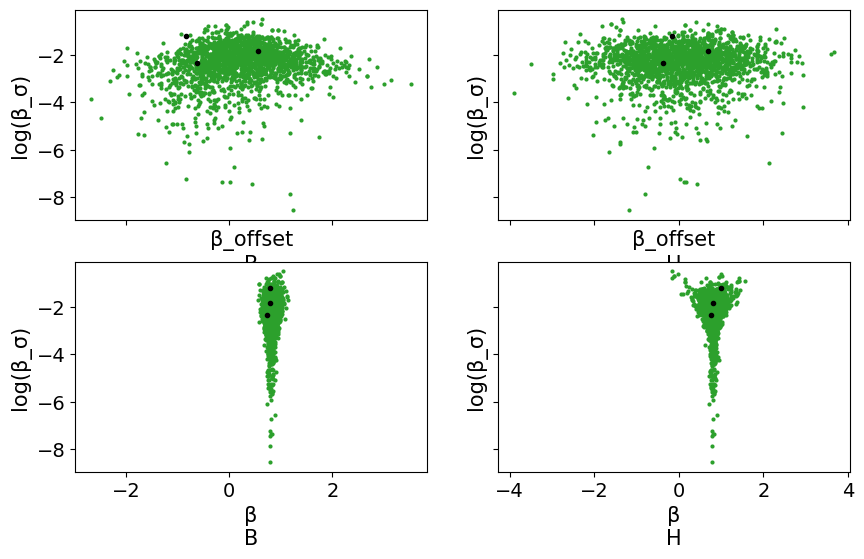

In [ ]:
idata_ncen.posterior["log(β_σ)"] = np.log(idata_ncen.posterior["β_σ"])

_, axes = plt.subplots(
    2, 2,
    sharey="row",
    sharex="col",
    figsize=(10, 6)
)

nvars = np.repeat(["β_offset", "β"], 2)

glabel = ["B", "H"] * 2

for ax, var, gl in zip(axes.ravel(), nvars, glabel):

    az.plot_pair(
        idata_ncen,
        var_names=[var, "log(β_σ)"],
        coords={"grupo": [gl]},
        divergences=True,
        scatter_kwargs={"color": "C2"},
        divergences_kwargs={
            "color": "k",
            "marker": ".",
            "mec": None
        },
        ax=ax,
    )


Veamos los valores estimados para $\alpha$ y $\beta$.  

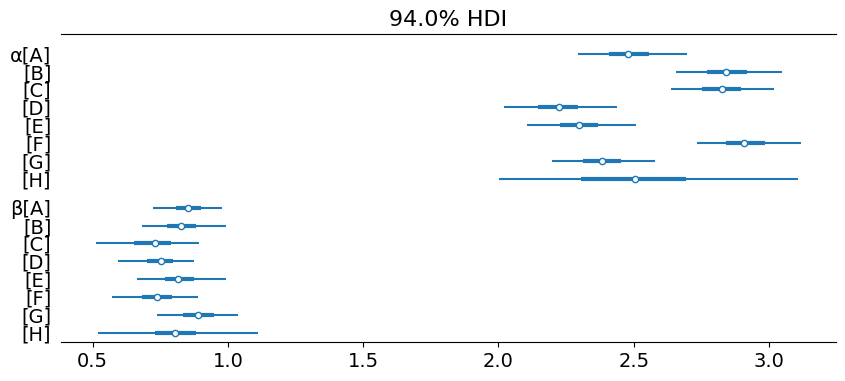

In [ ]:
az.plot_forest(idata_ncen, var_names=['α', 'β'], figsize=(10, 4), combined=True);

***Podemos ver que las estimaciones para el grupo H son las de mayor incertidumbre, esto concuerda con que tenemos un solo punto.***

Ahora vamos a ver las líneas ajustadas para los 8 grupos:

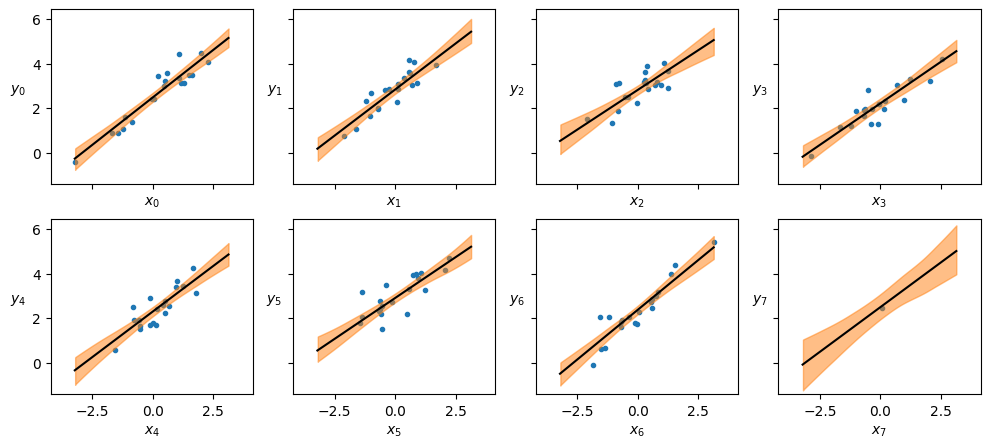

In [ ]:
_, ax = plt.subplots(
    2, 4,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

ax = np.ravel(ax)

j, k = 0, N

x_range = np.linspace(x_m.min(), x_m.max(), 10)

posterior = az.extract(idata_ncen)

for i, g in enumerate(grupos):

    ax[i].scatter(x_m[j:k], y_m[j:k], marker=".")

    ax[i].set_xlabel("$x_{}$".format(i))

    ax[i].set_ylabel("$y_{}$".format(i), labelpad=10, rotation=0)

    alfas = posterior["α"].sel(grupo=g)

    betas = posterior["β"].sel(grupo=g)

    alfa_m = alfas.mean("sample").item()

    beta_m = betas.mean("sample").item()

    ax[i].plot(
        x_range,
        alfa_m + beta_m * x_range,
        c="k"
    )

    az.plot_hdi(
        x_range,
        alfas + betas * xr.DataArray(x_range).transpose(),
        ax=ax[i]
    )

    plt.xlim(x_m.min() - 1, x_m.max() + 1)

    plt.ylim(y_m.min() - 1, y_m.max() + 1)

    j += N

    k += N


En el grupo H observamos que, a pesar de tener **una sola observación**, el modelo puede estimar una recta de regresión y una banda de incertidumbre alrededor de ella. Esto puede parecer extraño si pensamos en una regresión lineal independiente para cada grupo: con un solo punto no tendríamos información suficiente para estimar de manera razonable tanto una pendiente como un intercepto.

La diferencia está en que este no es un conjunto de regresiones independientes. En el modelo jerárquico, las pendientes e interceptos de los distintos grupos están relacionados a través de una distribución común. Por lo tanto, para estimar los parámetros del grupo H, el modelo utiliza tanto su única observación como la información aprendida a partir de los demás grupos.

Esto produce el llamado **partial pooling**: cada grupo conserva sus propios parámetros, pero esos parámetros no se estiman completamente por separado. Los grupos con muchos datos tienen mayor información propia, mientras que los grupos con pocos datos se benefician en mayor medida de la información compartida.

En particular, H es un buen ejemplo de esta idea. Su única observación aporta información sobre dónde debería ubicarse su recta, pero la forma general de la relación —por ejemplo, qué valores de pendiente son razonables— está fuertemente informada por los otros grupos. Por eso podemos obtener una estimación para H incluso cuando sus datos por sí solos no alcanzarían para ajustar una recta.

La banda de incertidumbre también nos permite ver esta diferencia: para un grupo con pocos datos esperamos mayor incertidumbre sobre su recta que para un grupo con muchas observaciones. El modelo no está “inventando” información para H, sino **combinando la poca información específica del grupo con la información compartida por toda la población de grupos**.


## Regresión lineal múltiple

Hasta ahora trabajamos con modelos en los que una única variable explicativa nos permitía describir o predecir una variable respuesta. Sin embargo, en muchas situaciones queremos incorporar simultáneamente varias características que pueden estar relacionadas con la variable que nos interesa estudiar.

Por ejemplo, podríamos querer explicar la calidad de un vino a partir de su acidez, densidad, graduación alcohólica, azúcar residual y contenido de sulfatos. También podríamos estudiar las calificaciones de un estudiante considerando, entre otras variables, el ingreso familiar, la distancia hasta la escuela y el nivel educativo de su madre.

La regresión lineal múltiple extiende el modelo de regresión lineal simple para incorporar varias variables explicativas. La idea general sigue siendo la misma: modelar la media de la variable respuesta a partir de una combinación lineal de las variables que incluimos en el modelo.

Si tenemos $k$ variables explicativas, podemos escribir:

$$ \mu = \alpha + \beta_1X_1+\beta_2X_2+\cdots+\beta_kX_k $$

donde $\alpha$ es la ordenada al origen y cada $\beta_j$ representa el efecto asociado a la variable $X_j$.

También podemos escribir esta expresión de manera más compacta utilizando notación matricial:

$$ \mu = \alpha + \mathbf{X}\boldsymbol{\beta} $$

donde $\mathbf{X}$ contiene los valores observados de las variables explicativas y $\boldsymbol{\beta}$ contiene sus correspondientes coeficientes.

En definitiva, la notación matricial no cambia la idea del modelo: simplemente permite escribir de forma más conveniente una suma de varios términos.

En una regresión lineal simple, con una única variable explicativa, buscamos una recta que describa la relación entre $X$ e $Y$. Cuando incorporamos varias variables, esa recta se generaliza a un hiperplano, cuya dimensión depende de la cantidad de variables explicativas.

Por lo tanto, conceptualmente, la regresión lineal múltiple no introduce una idea completamente nueva: seguimos construyendo una combinación lineal de variables para modelar la media de la respuesta. La principal diferencia es que ahora tenemos varios coeficientes y varias variables explicativas que deben interpretarse conjuntamente.

Veamos un ejemplo en el que estudiamos la relación entre  horas de estudio y horas de sueño, y notas de examen de estudiantes de primer año de una carrera universitaria.

In [ ]:
datos = pd.DataFrame({
    "estudio": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "sueno":   [5, 6, 5, 7, 6, 8, 7, 8, 7, 9],
    "nota":    [4, 4, 5, 5, 6, 7, 7, 8, 8, 9]
})

datos

,estudio,sueno,nota
0,1,5,4
1,2,6,4
2,3,5,5
3,4,7,5
4,5,6,6
5,6,8,7
6,7,7,7
7,8,8,8
8,9,7,8
9,10,9,9


Las variables involucradas son:

`nota:` variable respuesta $Y$

`estudio:` primera variable explicativa $X_1$

`sueño:` segunda variable explicativa $X_2$

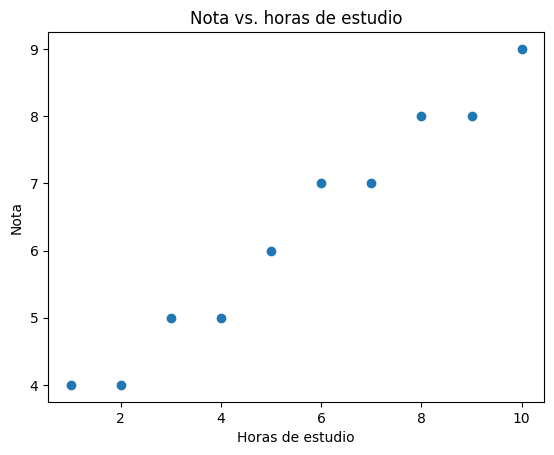

In [ ]:
plt.scatter(datos["estudio"], datos["nota"])
plt.xlabel("Horas de estudio")
plt.ylabel("Nota")
plt.title("Nota vs. horas de estudio")
plt.show()

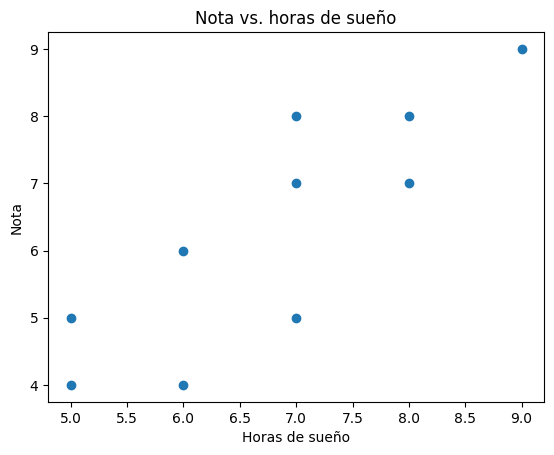

In [ ]:
plt.scatter(datos["sueno"], datos["nota"])
plt.xlabel("Horas de sueño")
plt.ylabel("Nota")
plt.title("Nota vs. horas de sueño")
plt.show()



Nuestro modelo tendrá la forma:



$$\mu=\alpha+\beta_{1}estudio+β_2sueño$$

donde $\mu$ corresponde al parámetro poblacional asociado a la distribución de las notas de examen.



### COnstruímos el modelo con PyMC:



In [ ]:
with pm.Model() as modelo_multiple:

    # Intercepto
    alpha = pm.Normal("alpha", mu=0, sigma=10)

    # Efecto de las horas de estudio
    beta_estudio = pm.Normal("beta_estudio", mu=0, sigma=2)

    # Efecto de las horas de sueño
    beta_sueno = pm.Normal("beta_sueno", mu=0, sigma=2)

    # Media esperada de la nota
    mu = pm.Deterministic(
        "mu",
        alpha
        + beta_estudio * datos["estudio"]
        + beta_sueno * datos["sueno"]
    )

    # Desvío residual
    sigma = pm.HalfNormal("sigma", sigma=2)

    # Variable observada
    nota = pm.Normal(
        "nota",
        mu=mu,
        sigma=sigma,
        observed=datos["nota"]
    )

Realizamos el muestreo correspondiente:

In [ ]:
with modelo_multiple:
    idata = pm.sample(
        1000,
        tune=1000,
        random_seed=123
    )

Output()

ERROR:pymc.stats.convergence:There were 154 divergences after tuning. Increase `target_accept` or reparameterize.
ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Estudiamos los coeficientes:

In [ ]:
az.summary(
    idata,
    var_names=["alpha", "beta_estudio", "beta_sueno", "sigma"]
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,2.838,0.891,0.759,4.336,0.041,0.064,469.0,385.0,1.10
beta_estudio,0.554,0.077,0.392,0.693,0.004,0.006,418.0,496.0,1.05
beta_sueno,0.062,0.176,-0.262,0.438,0.008,0.013,412.0,332.0,1.09
sigma,0.364,0.144,0.183,0.606,0.037,0.009,8.0,31.0,1.17


Ahora podemos comparar lo que observamos con lo que estima nuestro modelo. Cada punto representa un estudiante: en el eje horizontal tenemos su nota observada y en el vertical la nota media que predice el modelo. Cuanto más cerca estén los puntos de la diagonal, más parecidas son las predicciones a los valores observados.

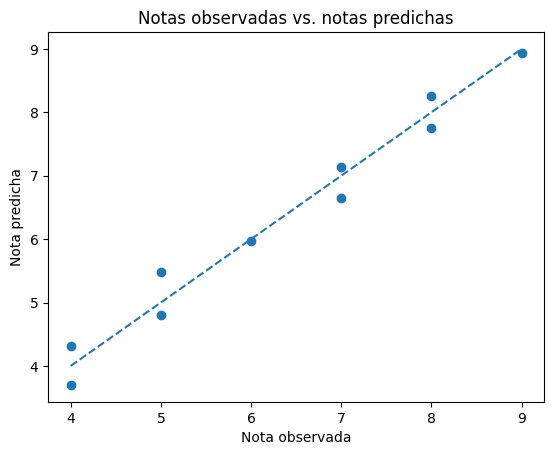

In [ ]:
mu_media = idata.posterior["mu"].mean(
    dim=("chain", "draw")
).values

plt.scatter(datos["nota"], mu_media)
plt.xlabel("Nota observada")
plt.ylabel("Nota predicha")
plt.title("Notas observadas vs. notas predichas")
plt.plot([4, 9], [4, 9], linestyle="--")
plt.show()

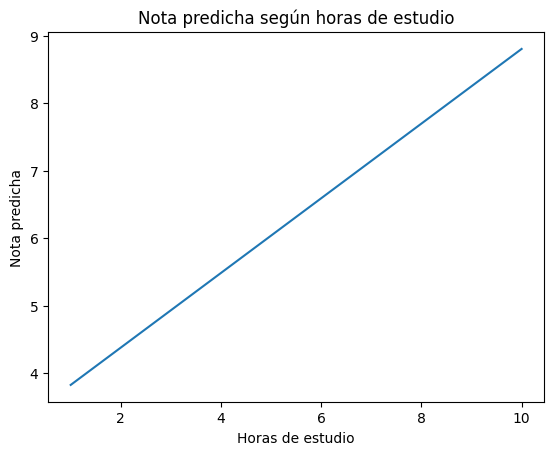

In [ ]:
estudio_nuevo = np.linspace(1, 10, 50)
sueno_fijo = 7

beta_estudio = idata.posterior["beta_estudio"].mean().item()
beta_sueno = idata.posterior["beta_sueno"].mean().item()
alpha = idata.posterior["alpha"].mean().item()

nota_predicha = (
    alpha
    + beta_estudio * estudio_nuevo
    + beta_sueno * sueno_fijo
)

plt.plot(estudio_nuevo, nota_predicha)
plt.xlabel("Horas de estudio")
plt.ylabel("Nota predicha")
plt.title("Nota predicha según horas de estudio")
plt.show()

Acá arriba podemos ver más claramente qué significa el coeficiente de estudio. Fijamos las horas de sueño en 7 y dejamos variar solamente las horas de estudio. Así podemos observar cómo cambia la nota esperada según el modelo.

Lo mismo si dejamos fijas las horas de estudio y queremos analizar horas de sueño vs notas:

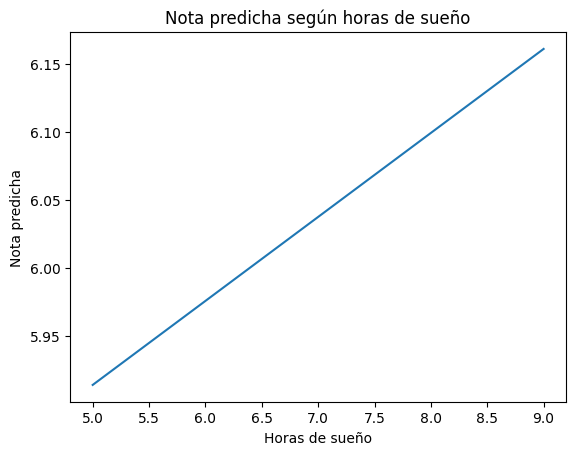

In [ ]:
sueno_nuevo = np.linspace(5, 9, 50)
estudio_fijo = 5

nota_predicha = (
    alpha
    + beta_estudio * estudio_fijo
    + beta_sueno * sueno_nuevo
)

plt.plot(sueno_nuevo, nota_predicha)
plt.xlabel("Horas de sueño")
plt.ylabel("Nota predicha")
plt.title("Nota predicha según horas de sueño")
plt.show()

## Regresión polinomial

La idea central es muy simple: partimos de una variable observada, por ejemplo hora, y creamos nuevas variables a partir de sus potencias.

$$ \mu = \beta_0+ \beta_1x+ \beta_2x^2+ \beta_3x^3+\cdots $$

Aunque aparezcan potencias de $x$, el modelo sigue siendo lineal en los parámetros $\beta$.

Un polinomio de grado bajo permite representar relaciones curvas sin abandonar el marco de la regresión.

In [ ]:
# Ajustamos un polinomio de grado 4
modelo_poly = bmb.Model(
    "alquiladas ~ poly(hora, 4)",
    bicis,
    family="negativebinomial"
)

# Obtenemos la distribución a posteriori
idata_poly = modelo_poly.fit()

Podemos visualizar la media estimada junto con los datos observados:

In [ ]:
# Graficamos la media estimada por el modelo
_, ax = plt.subplots(figsize=(10, 5))

bmb.interpret.plot_predictions(
    modelo_poly,
    idata_poly,
    "hora",
    ax=ax
)

# Agregamos los datos observados
ax.plot(
    bicis.hora,
    bicis.alquiladas,
    "C2.",
    zorder=-3
)

ax.set_xlabel("Hora")
ax.set_ylabel("Bicicletas alquiladas");

¿Qué deberíamos observar?

La línea representa la relación promedio que estima el modelo entre la hora y la cantidad de bicicletas alquiladas. Al permitir términos cuadráticos, cúbicos y de cuarto grado, la curva puede adaptarse a patrones que una recta no podría representar.

¿Por qué no aumentar indefinidamente el grado?

Un polinomio de grado alto puede volverse demasiado flexible. En lugar de capturar el patrón general de los datos, puede empezar a seguir variaciones pequeñas y producir comportamientos poco razonables en algunas regiones.

Una alternativa consiste en buscar flexibilidad local: en lugar de utilizar una única curva para todo el rango de \(x\), podemos construirla a partir de varias funciones que actúan en distintas regiones.

Ahí aparecen los splines.

## Splines

Podemos pensar un spline como una curva construida a partir de varias piezas que se combinan suavemente.

Los puntos donde cambia la función que utilizamos se denominan nudos (knots).

En lugar de elegir manualmente la forma completa de la curva, dejamos que el modelo determine cuánto contribuye cada una de estas funciones.

Para ilustrarlo, podemos ajustar un spline cúbico a las mismas variables:

In [ ]:
# Definimos algunos nudos a lo largo del rango de horas
knots = np.linspace(0, 23, 6)

# Ajustamos un spline cúbico
modelo_spline = bmb.Model(
    "alquiladas ~ bs(hora, degree=3, knots=knots)",
    bicis,
    family="negativebinomial"
)

# Obtenemos la distribución a posteriori
idata_spline = modelo_spline.fit()

Y nuevamente podemos mirar la relación estimada:

In [ ]:
# Graficamos la curva estimada
_, ax = plt.subplots(figsize=(10, 5))

bmb.interpret.plot_predictions(
    modelo_spline,
    idata_spline,
    "hora",
    ax=ax
)

# Mostramos los datos observados
ax.plot(
    bicis.hora,
    bicis.alquiladas,
    "C2.",
    zorder=-3
)

ax.set_xlabel("Hora")
ax.set_ylabel("Bicicletas alquiladas");

Polinomios y splines permiten modelar relaciones no lineales utilizando modelos de regresión.

Con un polinomio, buscamos una única función que describa todo el rango de los datos.
Con un spline, construimos una curva flexible a partir de varias funciones que actúan localmente.

En ambos casos, la idea es transformar la variable $x$ para poder representar relaciones más complejas que una recta.

## Selección de variables

Supongamos que queremos predecir el rendimiento de un cultivo y tenemos cuatro variables:

agua: cantidad de agua disponible;
temperatura: temperatura promedio;
horas_sol: horas de sol;
color_suelo: una variable que no aporta información real.

Vamos a generar los datos nosotros mismos. La gracia es que sabemos cómo fueron construidos, así que después podemos interpretar qué encuentra el modelo.

1. Generamos los datos

In [ ]:
np.random.seed(123)

n = 100

agua = np.random.normal(50, 10, n)
temperatura = np.random.normal(25, 3, n)
horas_sol = np.random.normal(8, 1, n)
color_suelo = np.random.normal(0, 1, n)

# El rendimiento depende de agua, temperatura y horas de sol
rendimiento = (
    2
    + 0.5 * agua
    - 0.8 * temperatura
    + 1.2 * horas_sol
    + np.random.normal(0, 5, n)
)

datos = pd.DataFrame({
    "rendimiento": rendimiento,
    "agua": agua,
    "temperatura": temperatura,
    "horas_sol": horas_sol,
    "color_suelo": color_suelo
})

Nosotros sabemos cómo fueron generados los datos:

agua participa en la generación del rendimiento;

temperatura participa en la generación del rendimiento;

horas_sol también participa, aunque con un efecto más pequeño;

color_suelo fue generado, pero no participa en la generación del rendimiento.

Sin embargo, en un problema real no conocemos esta información de antemano.

2. Creamos el modelo

Comenzamos ajustando un modelo que incluye todas las variables:

In [ ]:
modelo_completo = bmb.Model(
    "rendimiento ~ agua + temperatura + horas_sol + color_suelo",
    datos
)

idata_completo = modelo_completo.fit()

Este será nuestro modelo de referencia.

La idea es utilizarlo como punto de comparación para estudiar si podemos obtener modelos más pequeños con un comportamiento predictivo similar.

3. ¿Qué queremos encontrar?

Podemos plantearlo a los estudiantes así:

Tenemos un modelo con cuatro variables.
¿Podemos eliminar alguna variable sin perder prácticamente capacidad predictiva?

Para responder esta pregunta vamos a construir distintos modelos, desde uno muy pequeño hasta el modelo completo.

Por ejemplo:

In [ ]:
formulas = [
    "rendimiento ~ agua",
    "rendimiento ~ agua + temperatura",
    "rendimiento ~ agua + temperatura + horas_sol",
    "rendimiento ~ agua + temperatura + horas_sol + color_suelo"
]

Podemos pensar estos modelos como una secuencia:

$$ \begin{aligned} M_1 &: \text{agua}\\ M_2 &: \text{agua + temperatura}\\ M_3 &: \text{agua + temperatura + horas_sol}\\ M_4 &: \text{agua + temperatura + horas_sol + color_suelo} \end{aligned} $$

El modelo $M_4$ es nuestro modelo de referencia.

4. Ajustamos los modelos

Ahora ajustamos cada uno de los modelos:

In [ ]:
modelos = {}
idatas = {}

for i, formula in enumerate(formulas, start=1):

    # Creamos el modelo correspondiente
    modelo = bmb.Model(formula, datos)

    # Ajustamos el modelo
    idata = modelo.fit()

    # ¡Guardamos el modelo y sus resultados!
    modelos[f"M{i}"] = modelo
    idatas[f"M{i}"] = idata

Ahora tenemos cuatro modelos que podemos comparar.

5. ¿Cuál predice mejor?

Una posibilidad sería elegir simplemente el modelo con mayor cantidad de variables. Pero nuestro objetivo es encontrar un modelo que sea suficientemente pequeño pero que mantenga una buena capacidad predictiva.

Por eso podemos comparar los modelos utilizando LOO.

In [ ]:
comparacion = az.compare(
    idatas,
    ic="loo"
)

comparacion

Y visualizar la comparación:

In [ ]:
az.plot_compare(comparacion)

¿Cuánto cambia la capacidad predictiva cuando agregamos o quitamos variables?


| Modelo  | Variables | Idea                   |
| ------- | --------: | ---------------------- |
| $M_1$ |         1 | modelo muy pequeño     |
| $M_2$ |         2 | incorpora temperatura  |
| $M_3$ |         3 | incorpora horas de sol |
| $M_4$ |         4 | modelo de referencia   |


La decisión no consiste simplemente en buscar el modelo con más variables, sino que buscamos un modelo reducido que tenga un comportamiento predictivo suficientemente cercano al modelo de referencia.

